# Practical Lab 2: Multivariate Linear Regression, Non-Parametric Models and Cross-Validation

**Course:** CSCN8010 – Foundations of Machine Learning  
**Student:** Ubaid Ullah  
**Student ID:** 9110715

---

## Objective

The objective of this lab is to develop and evaluate machine learning models for predicting diabetes disease progression one year after baseline using the Scikit-Learn Diabetes dataset.

The lab consists of three parts:

1. **Part 1 – Data Preparation and Exploratory Data Analysis:** Understand the dataset, explore relationships between variables, examine data quality, and create training, validation, and test sets.
2. **Part 2 – Univariate Polynomial Regression:** Train and compare polynomial regression models of degrees 0 through 5 using BMI as the predictor.
3. **Part 3 – Multivariate and Non-Parametric Models:** Develop and compare additional models using multiple features, including polynomial regression, decision trees, and k-nearest neighbors, while addressing the Logistic Regression requirement.

Model performance will be evaluated using R-squared (R²), Mean Absolute Error (MAE), and Mean Absolute Percentage Error (MAPE).

---

## Part 1: Data Understanding, EDA, and Preparation

In [1]:
import sys
import sklearn
import pandas as pd

from sklearn.datasets import load_diabetes

# Verify environment
print("Python version:", sys.version.split()[0])
print("Scikit-Learn version:", sklearn.__version__)
print("Pandas version:", pd.__version__)

# Load diabetes dataset
diabetes = load_diabetes(as_frame=True, scaled=False)

print("\nDataset loaded successfully!")
print("Dataset shape:", diabetes.frame.shape)
print("Number of features:", len(diabetes.feature_names))
print("Features:", diabetes.feature_names)

Python version: 3.13.7
Scikit-Learn version: 1.9.1
Pandas version: 3.0.6

Dataset loaded successfully!
Dataset shape: (442, 11)
Number of features: 10
Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']



### 1.1 Problem Definition

The objective of this lab is to predict diabetes disease progression one year after baseline using patient health measurements.

The Scikit-Learn Diabetes dataset contains 442 patient records, with 10 input features including age, sex, body mass index (BMI), blood pressure, and six blood serum measurements.

**Machine Learning Problem Type:** Supervised Regression

This is a supervised learning problem because the dataset contains both input features and a known target value for each patient. It is a regression problem because the target is continuous and numerical rather than a category.

**Input Features (X):** Patient measurements such as BMI, age, blood pressure, and serum measurements.

**Target Variable (y):** A quantitative measure of diabetes disease progression one year after baseline.

**Business/Clinical Context:** The purpose is to investigate whether machine learning models can estimate disease progression and potentially support physicians in identifying patients who may require closer monitoring.

**Model Evaluation:** Models will be compared using R-squared (R²), Mean Absolute Error (MAE), and Mean Absolute Percentage Error (MAPE). Training and validation performance will help identify overfitting or underfitting, while the test set will be reserved for final evaluation.

**Important Limitation:** The target is a progression score, not a diagnosis or a direct probability of developing diabetes. Therefore, this lab evaluates predictive performance rather than establishing a clinically validated screening system.



### Connections to Previous Machine Learning Workshops

The following concepts from previous workshops help explain the approach used in this lab.

**1. Performance Metrics Classification Workshop**

In the classification workshop, we evaluated models using accuracy, precision, recall, F1-score, and confusion matrices. These metrics are appropriate for predicting categories, such as whether an image represents the digit 5.

In this lab, the target is a continuous diabetes progression score rather than a category. Therefore, we use regression metrics: R², MAE, and MAPE. Similar to classification, evaluating performance on unseen data is essential to understanding how well a model generalizes.

**2. K-Nearest Neighbor (KNN) Workshop**

The KNN workshop demonstrated how predictions can be made using nearby observations and how the choice of K affects model performance.

For regression, KNN predicts a numerical value based on neighboring training samples. Small K values may lead to overfitting, while large K values may produce overly smooth predictions. Feature scaling is also important because KNN depends on distances between observations.

In this lab, we will compare different KNN regression configurations using validation performance.

**3. Logistic Regression Classifier Workshop**

The Logistic Regression workshop introduced supervised classification, model training, and predictions based on learned parameters. It also demonstrated the importance of evaluating model performance and comparing models.

Although Logistic Regression contains the word "regression," it is primarily a classification algorithm. Unlike Logistic Regression, the models in this lab must predict a continuous numerical progression score.

The underlying principles of training models, controlling complexity, and evaluating generalization remain applicable.

### Generalization and Model Selection

To evaluate models fairly, we will divide the dataset into training (75%), validation (10%), and test (15%) sets.

The training set will be used to fit model parameters, the validation set to compare models and select hyperparameters, and the test set to estimate the final selected model's performance on unseen data.

We will examine both training and validation results to identify possible overfitting or underfitting and discuss these findings in the conclusion.


In [2]:
# Review the dataset documentation provided by Scikit-Learn
print(diabetes.DESCR)

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

In [3]:
# Create a working copy of the dataset
df = diabetes.frame.copy()

# Display the first five records
print("First five records:")
display(df.head())

# Display basic dataset information
print("\nDataset Information:")
df.info()

# Identify the independent and dependent variables
X = df.drop(columns="target")
y = df["target"]

print("\nFeature matrix shape:", X.shape)
print("Target vector shape:", y.shape)
print("Target data type:", y.dtype)

First five records:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB

Feature matrix shape: (442, 10)
Target vector shape: (442,)
Target data type: float64



### 1.3 Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the distribution, quality, and relationships of variables in the Diabetes dataset before building prediction models.

The analysis includes:

1. Descriptive statistics to understand central tendency, variability, and the range of measurements.
2. Histograms to examine feature distributions and the target variable.
3. Scatter plots to investigate relationships between input features and diabetes progression.
4. A correlation matrix to identify linear relationships between variables.
5. Data quality checks for missing values, duplicates, and potential outliers.

The findings will help us interpret model performance and make informed decisions about data preparation.



#### 1.3.1 Descriptive Statistics

We begin by examining the statistical properties of the dataset, including count, mean, standard deviation, minimum, maximum, median, and quartiles.

These statistics help us understand the distribution of patient measurements, identify variations between features, and recognize potential extreme values.


In [4]:
# Descriptive statistics for all numerical variables
summary_stats = df.describe().T

print("Descriptive Statistics:")
display(summary_stats.round(2))

# Additional target statistics
print("\nTarget Variable Summary:")
print(f"Mean: {df['target'].mean():.2f}")
print(f"Median: {df['target'].median():.2f}")
print(f"Standard Deviation: {df['target'].std():.2f}")
print(f"Minimum: {df['target'].min():.2f}")
print(f"Maximum: {df['target'].max():.2f}")
print(f"Skewness: {df['target'].skew():.2f}")

Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
age,442.0,48.52,13.11,19.00,38.25,50.00,59.00,79.00
sex,442.0,1.47,0.50,1.00,1.00,1.00,2.00,2.00
bmi,442.0,26.38,4.42,18.00,23.20,25.70,29.28,42.20
bp,442.0,94.65,13.83,62.00,84.00,93.00,105.00,133.00
s1,442.0,189.14,34.61,97.00,164.25,186.00,209.75,301.00
s2,442.0,115.44,30.41,41.60,96.05,113.00,134.50,242.40
s3,442.0,49.79,12.93,22.00,40.25,48.00,57.75,99.00
s4,442.0,4.07,1.29,2.00,3.00,4.00,5.00,9.09
s5,442.0,4.64,0.52,3.26,4.28,4.62,5.00,6.11
s6,442.0,91.26,11.50,58.00,83.25,91.00,98.00,124.00



Target Variable Summary:
Mean: 152.13
Median: 140.50
Standard Deviation: 77.09
Minimum: 25.00
Maximum: 346.00
Skewness: 0.44



#### 1.3.2 Initial Data Quality Inspection

The dataset is checked for missing values, duplicate records, and data types.

These checks help determine whether preprocessing is required. Potential outliers will be examined separately before deciding whether any observations should be modified or removed.


In [5]:
# Missing values
print("Missing values per column:")
display(df.isnull().sum().to_frame(name="Missing Values"))

# Duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Data types
print("\nColumn data types:")
display(df.dtypes.to_frame(name="Data Type"))

# Unique values
print("\nUnique values per column:")
display(df.nunique().to_frame(name="Unique Values"))

Missing values per column:


,Missing Values
age,0
sex,0
bmi,0
bp,0
s1,0
s2,0
s3,0
s4,0
s5,0
s6,0



Number of duplicate rows: 0

Column data types:


,Data Type
age,float64
sex,float64
bmi,float64
bp,float64
s1,float64
s2,float64
s3,float64
s4,float64
s5,float64
s6,float64



Unique values per column:


,Unique Values
age,58
sex,2
bmi,163
bp,100
s1,141
s2,302
s3,63
s4,66
s5,184
s6,56



#### 1.3.3 Distribution Analysis Using Histograms

Histograms are used to examine how the values of each variable are distributed.

We will inspect the distributions of all ten input features and the diabetes progression target to identify skewness, concentration of values, unusual observations, and possible outliers.


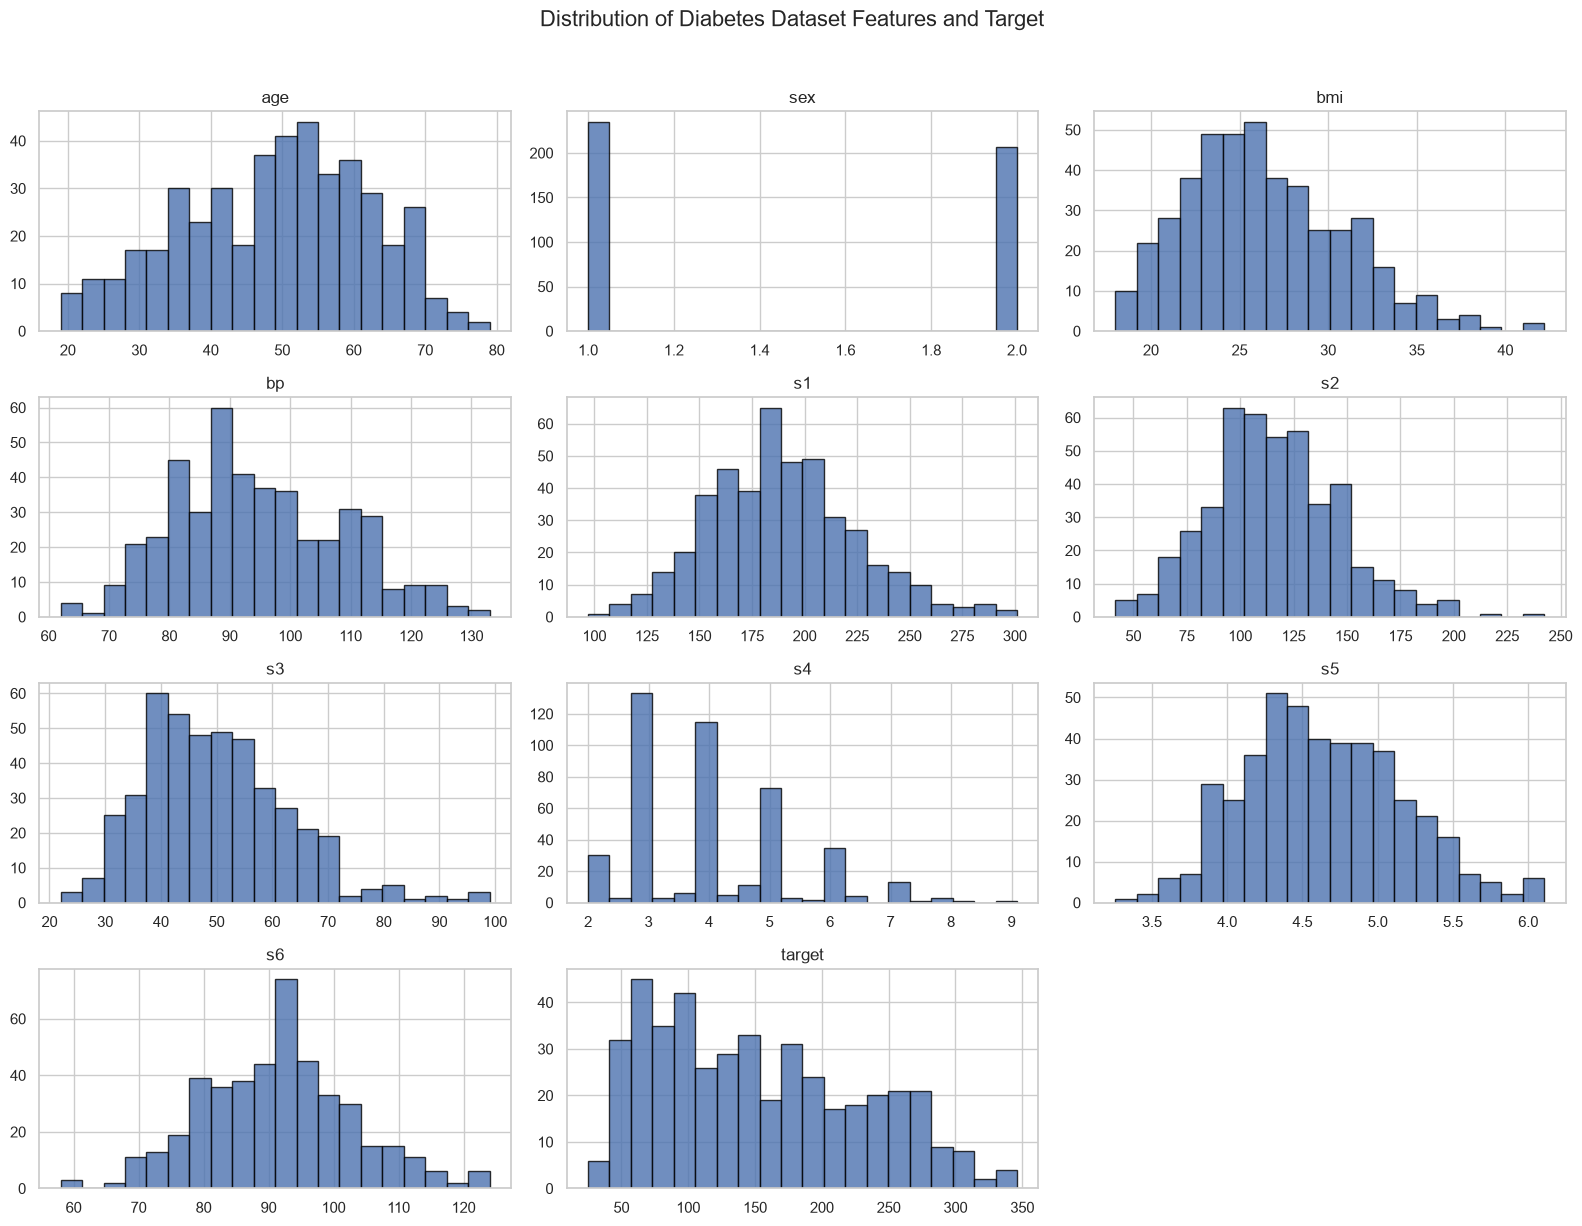

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Plot distributions of all features and the target
df.hist(
    bins=20,
    figsize=(16, 12),
    edgecolor="black",
    alpha=0.8
)

plt.suptitle(
    "Distribution of Diabetes Dataset Features and Target",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()


#### 1.3.4 Initial EDA Findings

The exploratory analysis provides the following observations:

**Dataset Completeness and Quality**
- The dataset contains 442 observations and 11 columns, including 10 predictors and one target variable.
- No missing values or duplicate records were detected.
- All columns are stored numerically. However, `sex` represents two encoded categories and should not be interpreted as a continuous measurement.

**Descriptive Statistics**
- The average patient age is 48.52 years, with ages ranging from 19 to 79.
- The average BMI is 26.38, with values ranging from 18.0 to 42.2.
- The diabetes progression target has a mean of 152.13, a median of 140.50, and a standard deviation of 77.09.
- The progression score ranges from 25 to 346, indicating substantial variation across patients.

**Distribution Analysis**
- BMI is concentrated around the mid-20s, with a right tail representing higher BMI observations.
- Several serum measurements show asymmetric or irregular distributions.
- The target has a skewness of 0.44, indicating a moderately right-skewed distribution.
- Potential extreme observations should be investigated before any data cleaning decisions.

**Implications for Modeling**

The dataset is sufficiently complete to proceed without immediate imputation or duplicate removal. The variation in the target indicates that predicting progression may be challenging. Relationships between individual features and the target must be examined further using scatter plots and correlation analysis.

These observations are descriptive and do not establish causal relationships.



#### 1.3.5 Scatter Plot Analysis

Scatter plots help visualize relationships between individual predictors and the diabetes progression target.

We examine age, BMI, blood pressure, and serum measurement `s5` to investigate whether higher or lower feature values are associated with changes in disease progression.

Linear trend lines are included to make general patterns easier to identify. These lines describe associations and do not establish causation.


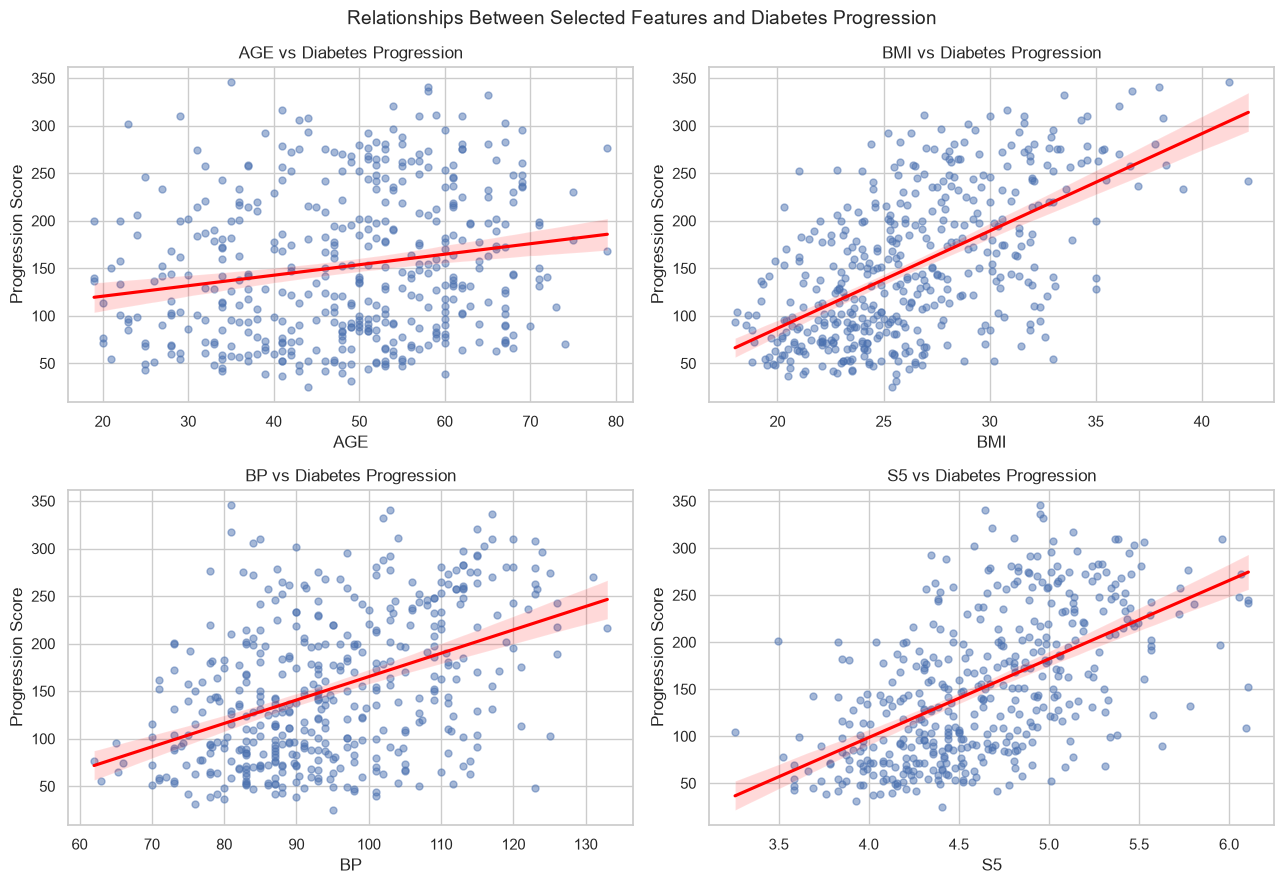

In [7]:
from src.diabetes_eda import DiabetesEDA

# Create an instance of the EDA class
eda = DiabetesEDA(df)

# Visualize relationships
eda.plot_scatter_relationships()


#### 1.3.6 Correlation Analysis

A Pearson correlation matrix is used to measure the strength and direction of linear relationships between numerical variables.

Correlation coefficients range from -1 to +1:

- **+1:** Perfect positive linear relationship.
- **0:** No linear relationship.
- **-1:** Perfect negative linear relationship.

We examine correlations with the target to identify potential predictors and correlations between features to identify possible multicollinearity.

Because `sex` is category-coded, its numerical correlation requires careful interpretation. Correlation does not imply causation.


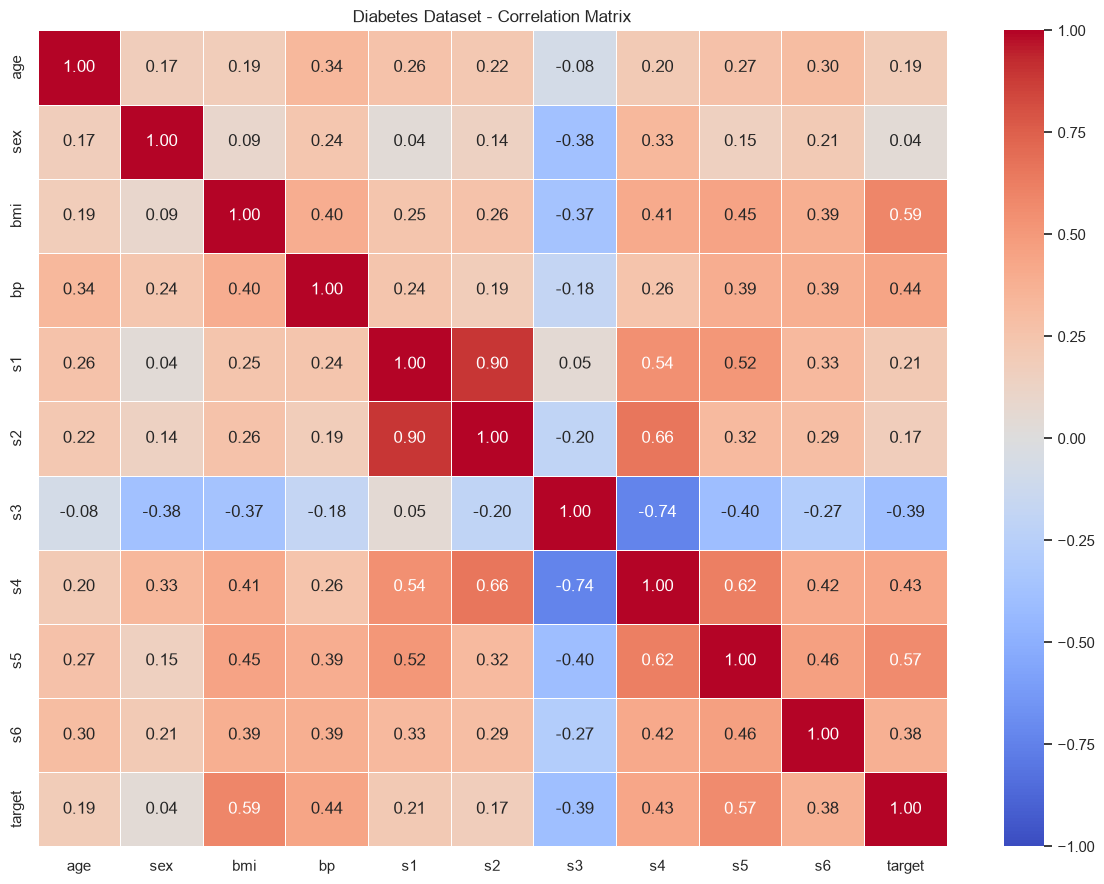

Feature Correlations with Diabetes Progression:


,Correlation with Target
bmi,0.586
s5,0.566
bp,0.441
s4,0.430
s6,0.382
s1,0.212
age,0.188
s2,0.174
sex,0.043
s3,-0.395


In [8]:
# Visualize correlation matrix
eda.plot_correlation_matrix()

# Rank correlations with diabetes progression
print("Feature Correlations with Diabetes Progression:")
display(
    eda.get_target_correlations()
    .to_frame(name="Correlation with Target")
    .round(3)
)


#### 1.3.7 Scatter Plot and Correlation Findings

**Scatter Plot Analysis**

The scatter plots reveal differences in how individual patient measurements relate to diabetes progression.

- **BMI:** Shows a clear positive relationship with the target. Patients with higher BMI values generally tend to have higher progression scores, although considerable variation remains.
- **S5:** Also demonstrates a noticeable positive association with disease progression.
- **Blood Pressure (BP):** Shows a moderate positive relationship, suggesting that blood pressure may contribute useful predictive information.
- **Age:** Has a relatively weak positive relationship with progression, indicating limited predictive ability when considered independently.

The considerable scatter around the trend lines suggests that relying on a single feature may not be sufficient for highly accurate predictions.

**Correlation Analysis**

The Pearson correlation matrix provides the following findings:

| Feature | Correlation with Target |
|---------|------------------------:|
| BMI | 0.586 |
| S5 | 0.566 |
| BP | 0.441 |
| S4 | 0.430 |
| S6 | 0.382 |
| S3 | -0.395 |
| Age | 0.188 |
| Sex | 0.043 |

BMI has the strongest positive linear correlation with diabetes progression, followed by S5. This supports using BMI for the univariate polynomial regression models in Part 2.

S3 has the strongest negative correlation with the target, indicating that higher S3 values tend to be associated with lower progression scores.

**Potential Multicollinearity**

The correlation matrix also reveals strong relationships between some predictors:

- S1 and S2: approximately 0.90
- S3 and S4: approximately -0.74

These relationships suggest potential multicollinearity, which can affect the stability and interpretation of regression coefficients.

Feature removal is not automatically necessary. We will consider these relationships when evaluating multivariate models in Part 3.

**Implications for Model Development**

1. BMI is an appropriate starting feature for univariate polynomial regression.
2. Additional features such as S5 and BP may improve predictive performance in multivariate models.
3. Weak individual correlation does not necessarily mean a feature has no predictive value when combined with others.
4. Training and validation results will be used to determine whether increasing model complexity improves generalization.

These results describe statistical associations rather than causal relationships.



#### 1.3.8 Outlier Detection Using the IQR Method

Potential outliers are examined using the Interquartile Range (IQR) method and boxplots.

The IQR is calculated as:

IQR = Q3 - Q1

Values below Q1 - 1.5 × IQR or above Q3 + 1.5 × IQR are flagged as potential outliers.

The encoded categorical feature `sex` is excluded from this analysis because the IQR method is not appropriate for its category codes.

The target variable is included for descriptive analysis but will not be used to remove observations automatically.

Outliers are not necessarily errors. Extreme patient measurements may represent legitimate clinical observations, so removal or modification requires additional justification.


IQR-Based Outlier Summary:


,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %
Feature,,,,,,,
age,38.25,59.00,20.75,7.12,90.12,0,0.00
bmi,23.20,29.28,6.07,14.09,38.39,3,0.68
bp,84.00,105.00,21.00,52.50,136.50,0,0.00
s1,164.25,209.75,45.50,96.00,278.00,8,1.81
s2,96.05,134.50,38.45,38.37,192.18,7,1.58
s3,40.25,57.75,17.50,14.00,84.00,7,1.58
s4,3.00,5.00,2.00,0.00,8.00,2,0.45
s5,4.28,5.00,0.72,3.20,6.08,4,0.90
s6,83.25,98.00,14.75,61.12,120.12,9,2.04


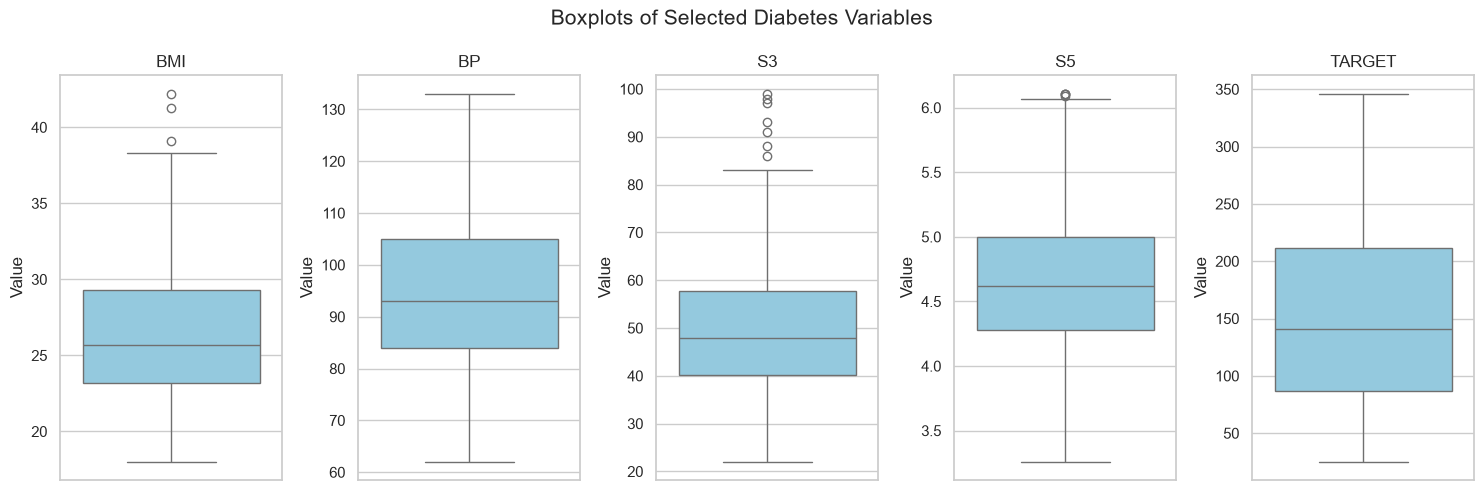

In [9]:

# Generate outlier report using our OOP class
outlier_summary = eda.outlier_report()

print("IQR-Based Outlier Summary:")
display(outlier_summary.round(2))

# Visualize selected variables
eda.plot_boxplots()



#### 1.3.9 Outlier Analysis Findings

The IQR method and boxplots identified several potential outliers in the diabetes dataset.

**Key Findings:**

- BMI contains 3 potential outliers (0.68%).
- S1 contains 8 potential outliers (1.81%).
- S2 and S3 each contain 7 potential outliers (1.58%).
- S4 contains 2 potential outliers (0.45%).
- S5 contains 4 potential outliers (0.90%).
- S6 contains 9 potential outliers (2.04%).
- Age, blood pressure, and the target variable have no outliers under the 1.5 × IQR rule.

The boxplots confirm the presence of several unusually high measurements, particularly for BMI and S3.

However, statistical outliers do not necessarily represent incorrect data. These observations may reflect genuine differences between patients.

Since no evidence of measurement errors has been identified, the outliers will be retained. Their possible influence on model performance will be considered during evaluation.

**Conclusion:** No automatic outlier removal or capping will be performed.



### 1.4 Data Cleaning and Preprocessing Decisions

Before model development, the dataset was examined for missing values, duplicated records, inconsistent data types, and potential outliers.

**Data Quality Assessment:**

| Check | Result | Decision |
|-------|--------|----------|
| Missing values | 0 | No imputation required |
| Duplicate records | 0 | No duplicates to remove |
| Data types | All numeric | No type conversion required |
| Encoded categorical feature | Sex (1 and 2) | Retain binary encoding |
| Potential outliers | Identified in several features | Retain observations |
| Target variable | Continuous numerical score | No target transformation required |

**Cleaning Decisions:**

The dataset is complete and does not require missing-value imputation or duplicate removal.

Although the IQR method identified some extreme observations, these values cannot be assumed to be errors. Therefore, all 442 patient records will be preserved.

The `sex` feature is represented using two numerical codes. Its existing binary encoding will be retained, while recognizing that its values represent categories rather than a continuous quantity.

Feature scaling will be applied within appropriate model pipelines, particularly for distance-based models such as KNN. Any fitted preprocessing transformations will be learned from the training set only to prevent data leakage.

**Final Decision:**

No records or features will be removed during the initial cleaning stage. The original feature values will be retained for model development, and the effects of model complexity and extreme observations will be considered during evaluation.


In [10]:
# Create a clean working copy without modifying the original data
df_clean = df.copy()

# Verify data integrity
assert df_clean.isna().sum().sum() == 0, "Missing values detected"
assert df_clean.duplicated().sum() == 0, "Duplicate records detected"
assert df_clean.shape == df.shape, "Dataset shape changed unexpectedly"

print("Data cleaning verification successful!")
print("Original dataset shape:", df.shape)
print("Clean dataset shape:", df_clean.shape)
print("Missing values:", df_clean.isna().sum().sum())
print("Duplicate records:", df_clean.duplicated().sum())
print("All original observations retained:", len(df_clean) == len(df))

Data cleaning verification successful!
Original dataset shape: (442, 11)
Clean dataset shape: (442, 11)
Missing values: 0
Duplicate records: 0
All original observations retained: True



### 1.5 Train, Validation, and Test Split

The cleaned dataset is divided into three mutually exclusive subsets to support model development and fair evaluation.

**Dataset Split:**

- **Training Set (75%):** Used to fit model parameters.
- **Validation Set (10%):** Used to compare models, select hyperparameters, and identify the best-performing configuration.
- **Test Set (15%):** Reserved for final evaluation after model selection.

The splitting process uses `train_test_split()` from Scikit-Learn with `random_state=42` to ensure reproducibility.

Since the dataset contains 442 observations, the split percentages are approximated using whole numbers of patient records.

The same split will be reused across Parts 2 and 3 to ensure consistent model comparisons.

Any preprocessing that learns parameters from data, such as feature scaling, will be fitted using the training set only. The test set will not be used for model selection or hyperparameter tuning.


In [11]:

from src.data_preparation import DiabetesDataPreparation

# Initialize our OOP data preparation class
data_preparation = DiabetesDataPreparation(
    dataframe=df_clean,
    random_state=42
)

# Perform the required split
splits = data_preparation.split_data()

X_train = splits["X_train"]
X_val = splits["X_val"]
X_test = splits["X_test"]

y_train = splits["y_train"]
y_val = splits["y_val"]
y_test = splits["y_test"]

# Summarize the split
split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test", "Total"],
    "Samples": [
        len(X_train),
        len(X_val),
        len(X_test),
        len(df_clean)
    ],
    "Percentage": [
        len(X_train) / len(df_clean) * 100,
        len(X_val) / len(df_clean) * 100,
        len(X_test) / len(df_clean) * 100,
        100.0
    ]
})

print("Train / Validation / Test Split:")
display(split_summary.round(2))

print("\nFeature and target shapes:")
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_val:  ", X_val.shape, "| y_val:  ", y_val.shape)
print("X_test: ", X_test.shape, "| y_test:", y_test.shape)


Train / Validation / Test Split:


,Dataset,Samples,Percentage
0,Training,332,75.11
1,Validation,44,9.95
2,Test,66,14.93
3,Total,442,100.00



Feature and target shapes:
X_train: (332, 10) | y_train: (332,)
X_val:   (44, 10) | y_val:   (44,)
X_test:  (66, 10) | y_test: (66,)


In [12]:

# Verify that no patient appears in multiple sets
train_indices = set(X_train.index)
val_indices = set(X_val.index)
test_indices = set(X_test.index)

assert train_indices.isdisjoint(val_indices)
assert train_indices.isdisjoint(test_indices)
assert val_indices.isdisjoint(test_indices)

# Verify every original observation is included
all_indices = train_indices | val_indices | test_indices

assert all_indices == set(df_clean.index)

# Verify features and targets remain aligned
assert X_train.index.equals(y_train.index)
assert X_val.index.equals(y_val.index)
assert X_test.index.equals(y_test.index)

print("Data split verification successful!")
print("No overlapping observations: PASS")
print("All 442 observations accounted for: PASS")
print("Features and targets correctly aligned: PASS")


Data split verification successful!
No overlapping observations: PASS
All 442 observations accounted for: PASS
Features and targets correctly aligned: PASS



### 1.6 Part 1 Summary

In Part 1, we loaded and explored the Scikit-Learn Diabetes dataset containing 442 patients, 10 predictors, and a continuous diabetes progression target.

Exploratory Data Analysis included descriptive statistics, histograms, scatter plots, a correlation matrix, and IQR-based outlier detection.

BMI and S5 demonstrated the strongest positive correlations with the target, while S3 had a negative correlation. Strong relationships between certain predictors also suggested potential multicollinearity.

Data quality checks identified no missing values or duplicate observations. Although several potential outliers were detected, they were retained because no evidence indicated that they were erroneous.

The dataset was divided into approximately 75% training, 10% validation, and 15% testing using a reproducible random split.

The training and validation sets will support model development and selection, while the test set will remain reserved for final evaluation.

Part 2 will investigate univariate polynomial regression models of degrees 0 through 5 using BMI as the predictor.



---

## Part 2: Univariate Polynomial Regression Using BMI

### 2.1 Model Development

In this part, six polynomial regression models with degrees ranging from 0 to 5 are trained to predict diabetes progression using only BMI.

The objective is to investigate how polynomial complexity affects model performance and generalization.

- Degree 0 represents a constant baseline prediction.
- Degree 1 represents simple linear regression.
- Degrees 2 through 5 introduce increasingly flexible nonlinear relationships.

Each model is trained on the same training dataset and evaluated using the same validation dataset.

A Scikit-Learn Pipeline combines feature scaling, polynomial feature generation, and linear regression. Scaling is learned from training data only to avoid data leakage.

The models will be evaluated using R², MAE, and MAPE. Validation results will be used for model selection, while the test set will remain untouched until the best model is chosen.


In [13]:
from src.univariate_polynomial import UnivariatePolynomialRegression

# Initialize our OOP polynomial regression class
poly_models = UnivariatePolynomialRegression(
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val
)

# Train polynomial models of degrees 0 through 5
trained_models = poly_models.train_models()

print("Polynomial regression training completed!")
print("Total models trained:", len(trained_models))
print("Polynomial degrees:", list(trained_models.keys()))

Polynomial regression training completed!
Total models trained: 6
Polynomial degrees: [0, 1, 2, 3, 4, 5]



### 2.2 Training and Validation Model Comparison

The six polynomial regression models are evaluated using the following metrics:

- **R²:** Measures how well the model explains variation in the target. Higher values are generally better.
- **MAE:** Measures the average absolute difference between actual and predicted progression scores. Lower values are better.
- **MAPE:** Measures the average absolute percentage prediction error. Lower values are better.

Training and validation results are reported separately to help identify underfitting, overfitting, and the effect of increasing polynomial degree.

The validation set will be used to select the best-performing model before final testing.


In [14]:
# Compare training and validation results
polynomial_results = poly_models.compare_models()

print("Polynomial Regression Model Comparison:")
display(polynomial_results.round(3))

Polynomial Regression Model Comparison:


,Degree,Train R2,Validation R2,Train MAE,Validation MAE,Train MAPE (%),Validation MAPE (%)
0,0,0.000,-0.069,65.072,71.503,61.848,59.148
1,1,0.334,0.522,51.638,47.539,47.762,40.929
2,2,0.334,0.523,51.620,47.232,47.748,40.742
3,3,0.334,0.520,51.651,47.300,47.797,40.904
4,4,0.337,0.506,51.517,48.622,47.520,40.949
5,5,0.341,0.449,51.237,50.287,47.403,41.172



### 2.3 Model Comparison and Selection

Six polynomial regression models, with degrees 0 through 5, were trained using BMI as the only predictor.

**Key Findings:**

1. **Degree 0:** The baseline model achieved a validation R² of -0.069 and an MAE of 71.503. Its constant predictions do not capture the relationship between BMI and disease progression.

2. **Degree 1:** Linear regression significantly improved performance, achieving a validation R² of 0.522 and MAE of 47.539.

3. **Degree 2:** The quadratic model achieved the best validation performance:
   - R²: 0.523
   - MAE: 47.232
   - MAPE: 40.742%

4. **Degrees 3–5:** Increasing polynomial complexity did not improve validation performance. Degree 5 achieved a slightly higher training R² than Degree 2, but its validation R² decreased to 0.449. This suggests that additional complexity may reduce generalization.

**Selected Model: Degree 2 Polynomial Regression**

Degree 2 is selected because it achieved the highest validation R² and the lowest validation MAE and MAPE.

However, its improvement over Degree 1 is small. Therefore, the additional complexity provides only a marginal benefit over ordinary linear regression.

The validation R² of 0.523 indicates that the selected model explains approximately 52.3% of the variation in diabetes progression within the validation set.

The remaining unexplained variation suggests that BMI alone is insufficient for highly accurate predictions.

The selected model will now be evaluated once on the previously unseen test set.



### 2.4 Final Evaluation on the Test Set

After selecting the Degree 2 polynomial regression model using validation performance, the model is evaluated on the previously unseen test set.

The test set contains 66 observations, representing approximately 15% of the original dataset.

The model was fitted using the training data only. The validation set was used for model selection, and the test set was reserved for final evaluation.

The same three metrics are calculated: R², MAE, and MAPE.

This evaluation provides an estimate of how well the selected model generalizes to unseen observations.


In [15]:

# Select the best model based on validation R2
best_index = polynomial_results["Validation R2"].idxmax()

best_degree = int(
    polynomial_results.loc[best_index, "Degree"]
)

best_model = trained_models[best_degree]

print("Selected Polynomial Degree:", best_degree)

# Use only BMI for the univariate model
X_test_bmi = X_test[["bmi"]].copy()

# Predict unseen test observations
y_test_pred = best_model.predict(X_test_bmi)

# Calculate test metrics using our OOP class
test_metrics = poly_models.calculate_metrics(
    y_test,
    y_test_pred
)

# Create a professional results table
test_results = pd.DataFrame([{
    "Model": f"Polynomial Degree {best_degree}",
    "Test R2": test_metrics["R2"],
    "Test MAE": test_metrics["MAE"],
    "Test MAPE (%)": test_metrics["MAPE (%)"]
}])

print("\nFinal Test Set Evaluation:")
display(test_results.round(3))


Selected Polynomial Degree: 2

Final Test Set Evaluation:


,Model,Test R2,Test MAE,Test MAPE (%)
0,Polynomial Degree 2,0.215,54.842,48.386



### 2.5 Test Set Performance Analysis

The selected Degree 2 polynomial regression model was evaluated on the previously unseen test set containing 66 observations.

**Test Results:**

- **R²:** 0.215
- **MAE:** 54.842
- **MAPE:** 48.386%

**Interpretation:**

The test R² of 0.215 indicates that the model explains approximately 21.5% of the variation in diabetes progression within the test set.

The MAE of 54.842 indicates that predictions differ from actual progression scores by approximately 54.84 units on average.

The MAPE of 48.386% indicates substantial relative prediction errors.

Compared with validation performance, the model's test R² decreased from 0.523 to 0.215, while MAE increased from 47.232 to 54.842.

This performance reduction suggests that the model does not generalize as well to the test observations as its validation results initially indicated.

Possible explanations include limited predictive information from BMI alone, variation between the relatively small data subsets, and relationships that a univariate quadratic model cannot capture.

However, these results alone do not establish overfitting.

The model was selected using validation performance only, and no modifications were made based on the test results.

**Conclusion:**

Although Degree 2 achieved the best validation performance among the six polynomial models, its test results demonstrate important predictive limitations. Additional patient features may help improve performance in Part 3.

The model is not sufficiently validated for clinical screening or medical decision-making.



### 2.6 Visualization of the Selected Polynomial Model

The selected Degree 2 polynomial regression model is visualized against the training, validation, and test datasets.

Three side-by-side scatter plots show the actual diabetes progression scores for each subset.

The red curve represents predictions from the same model trained exclusively on the training dataset. The model is not refitted using validation or test observations.

The plots share the same BMI and progression-score axes to support visual comparison.

This visualization helps assess how well the model captures the relationship between BMI and disease progression across unseen observations.


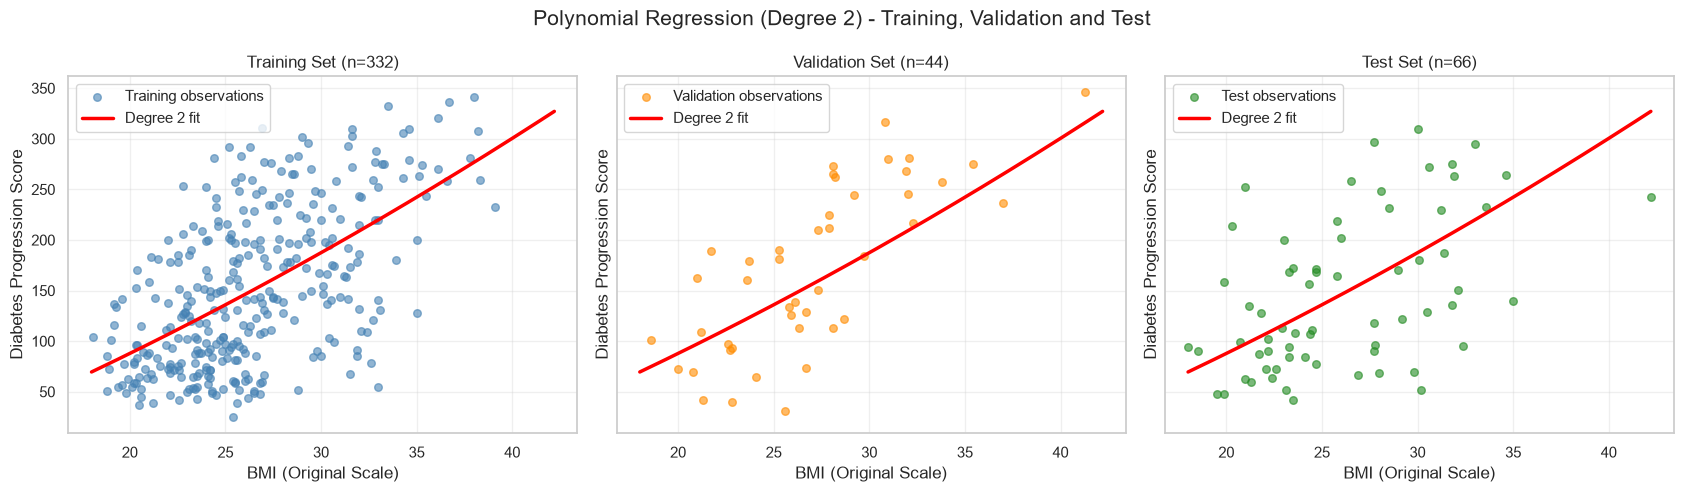

In [16]:
# Plot the trained Degree 2 model across all three datasets
poly_models.plot_model_across_splits(
    degree=best_degree,
    X_test=X_test,
    y_test=y_test
)


#### 2.6.1 Interpretation of the Polynomial Regression Plots

The Degree 2 polynomial model shows a positive relationship between BMI and predicted diabetes progression.

**Training Set:** The model captures the overall upward trend, but many observations are widely distributed around the fitted curve.

**Validation Set:** The predictions generally follow the observed trend. However, the considerable scatter indicates that BMI alone does not explain all variation in the target.

**Test Set:** Several observations differ substantially from the model's predictions, including patients with similar BMI values but very different progression scores. This is consistent with the lower test R² of 0.215.

The fitted curve shows relatively little curvature, which helps explain why the Degree 2 model only slightly outperformed the Degree 1 model during validation.

**Conclusion:** The visualization confirms that BMI has predictive value, but additional patient features may be needed to improve accuracy. The observed relationships are associations, not evidence of causation.



### 2.7 Equation of the Selected Polynomial Model

The selected Degree 2 polynomial regression model predicts diabetes progression using BMI and its squared term.

The general equation is:

\[
\hat{y} = b_0 + b_1(BMI) + b_2(BMI)^2
\]

Since the model pipeline includes StandardScaler, the fitted coefficients are transformed back to the original BMI scale before reporting the equation.

The coefficients are displayed to two decimal places for readability. Full-precision coefficients are retained for predictions and numerical calculations.


In [17]:

# Extract coefficients in original BMI units
coefficients = poly_models.get_quadratic_coefficients(
    degree=best_degree
)

b0 = coefficients["Intercept"]
b1 = coefficients["BMI"]
b2 = coefficients["BMI Squared"]

print("Best Model: Polynomial Degree", best_degree)

print("\nCoefficients (Original BMI Scale):")
for name, value in coefficients.items():
    print(f"{name}: {value:.6f}")

print("\nPolynomial Equation (2 Decimal Places):")
print(
    f"Predicted Progression = "
    f"{b0:.2f} {b1:+.2f} × BMI "
    f"{b2:+.2f} × BMI²"
)

# Verify that the original-scale equation agrees
# with the trained model's predictions
bmi_check = pd.DataFrame({
    "bmi": [20.0, 25.0, 30.0, 35.0]
})

pipeline_predictions = best_model.predict(bmi_check)

equation_predictions = (
    b0
    + b1 * bmi_check["bmi"].to_numpy()
    + b2 * bmi_check["bmi"].to_numpy() ** 2
)

import numpy as np

np.testing.assert_allclose(
    equation_predictions,
    pipeline_predictions,
    rtol=1e-10,
    atol=1e-8
)

print("\nEquation verification: PASS")


Best Model: Polynomial Degree 2

Coefficients (Original BMI Scale):
Intercept: -70.853178
BMI: 6.586365
BMI Squared: 0.067397

Polynomial Equation (2 Decimal Places):
Predicted Progression = -70.85 +6.59 × BMI +0.07 × BMI²

Equation verification: PASS



### 2.8 Predicting Diabetes Progression for a Selected BMI

To demonstrate how the trained model generates predictions, a BMI value of 30 is selected.

This value falls within the observed dataset range.

The trained Degree 2 polynomial model is used through its `predict()` method. The prediction is expressed in the target's progression-score units, not as a probability or a clinical diagnosis.


In [18]:
# Choose an example BMI
chosen_bmi = 30.0

# Predict through our OOP class
predicted_progression = poly_models.predict_for_bmi(
    degree=best_degree,
    bmi_value=chosen_bmi
)

print(f"Selected BMI: {chosen_bmi:.1f}")
print(
    f"Predicted Diabetes Progression: "
    f"{predicted_progression:.2f}"
)

Selected BMI: 30.0
Predicted Diabetes Progression: 187.39



**Precision Note:** The polynomial equation is displayed with two-decimal coefficients as requested. However, rounding the quadratic coefficient to two decimal places introduces noticeable prediction differences because BMI is squared. Therefore, a six-decimal version is also reported for more accurate interpretation. All predictions use the original full-precision trained model.



### 2.9 Number of Trainable Parameters

The number of trainable parameters in a univariate polynomial regression model depends on its polynomial degree.

For a polynomial of degree `d`, the number of trainable regression coefficients is:

\[
\text{Parameters} = d + 1
\]

The additional parameter represents the intercept (constant term).

For example:

- Degree 0 fits 1 parameter (constant).
- Degree 1 fits 2 parameters (constant and BMI).
- Degree 2 fits 3 parameters (constant, BMI, and BMI squared).
- Degree 5 fits 6 parameters (constant and powers of BMI through degree 5).

The Scikit-Learn `get_feature_names_out()` method is used to identify the polynomial terms.

In our pipeline, `PolynomialFeatures(include_bias=True)` generates the constant term, while `LinearRegression(fit_intercept=False)` prevents fitting an additional, redundant intercept.

The feature scaling statistics are not counted as trainable regression coefficients.

Higher-degree models contain more trainable parameters, allowing increased flexibility but potentially increasing the risk of overfitting.


In [19]:
# Display polynomial terms and trainable parameter counts
parameter_table = poly_models.parameter_summary()

print("Trainable Parameters for Polynomial Models:")
display(parameter_table)

# Verify expected counts
assert all(
    parameter_table["Trainable Parameters"]
    == parameter_table["Degree"] + 1
)

print("\nParameter count verification: PASS")

Trainable Parameters for Polynomial Models:


,Degree,Polynomial Terms,Trainable Parameters
0,0,1,1
1,1,"1, bmi_scaled",2
2,2,"1, bmi_scaled, bmi_scaled^2",3
3,3,"1, bmi_scaled, bmi_scaled^2, bmi_scaled^3",4
4,4,"1, bmi_scaled, bmi_scaled^2, bmi_scaled^3, bmi...",5
5,5,"1, bmi_scaled, bmi_scaled^2, bmi_scaled^3, bmi...",6



Parameter count verification: PASS



### 2.10 Error Analysis and Model Limitations

To investigate where the selected Degree 2 polynomial regression model fails, we examine individual prediction errors on the held-out test set.

The residual is defined as:

\[
Residual = Actual - Predicted
\]

A positive residual indicates that the model underestimated progression, while a negative residual indicates overestimation.

The analysis includes:

1. Actual versus predicted progression scores.
2. Residuals plotted against BMI.
3. The distribution of prediction residuals.
4. The five observations with the largest absolute prediction errors.
5. Summary statistics describing prediction accuracy and error direction.

These diagnostics help identify potential systematic errors, large prediction mistakes, and limitations of using BMI alone.

The test set is used only for final evaluation and descriptive error analysis. No model selection, tuning, or retraining will be performed using test results.


Test Error Summary:


,Measure,Value
0,Test observations,66.00
1,Mean signed residual,-2.37
2,Median absolute error,47.65
3,Maximum absolute error,154.82
4,Patients with absolute error > 50,32.00
5,Underpredicted observations,29.00
6,Overpredicted observations,37.00



Five Largest Prediction Errors:


,BMI,Actual,Predicted,Residual,Absolute Error,Absolute Percentage Error (%)
78,21.0,252.0,97.18,154.82,154.82,61.44
56,30.2,52.0,189.52,-137.52,137.52,264.47
113,27.7,297.0,163.30,133.70,133.70,45.02
218,20.3,214.0,90.62,123.38,123.38,57.65
9,30.0,310.0,187.39,122.61,122.61,39.55


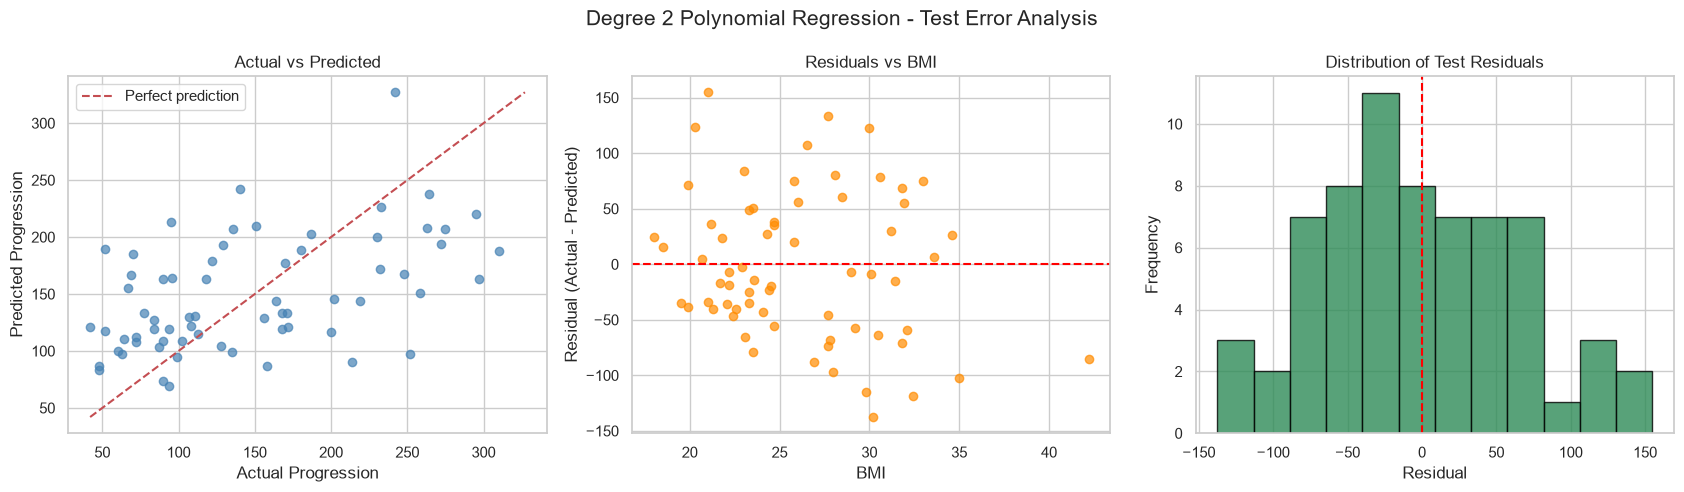

In [20]:

# Analyze the selected model's test predictions
test_errors = poly_models.get_test_error_report(
    degree=best_degree,
    X_test=X_test,
    y_test=y_test
)

# Summary of prediction errors
error_summary = pd.DataFrame({
    "Measure": [
        "Test observations",
        "Mean signed residual",
        "Median absolute error",
        "Maximum absolute error",
        "Patients with absolute error > 50",
        "Underpredicted observations",
        "Overpredicted observations"
    ],
    "Value": [
        len(test_errors),
        test_errors["Residual"].mean(),
        test_errors["Absolute Error"].median(),
        test_errors["Absolute Error"].max(),
        (test_errors["Absolute Error"] > 50).sum(),
        (test_errors["Residual"] > 0).sum(),
        (test_errors["Residual"] < 0).sum()
    ]
})

print("Test Error Summary:")
display(error_summary.round(2))

print("\nFive Largest Prediction Errors:")
display(
    test_errors.nlargest(
        5, "Absolute Error"
    ).round(2)
)

# Plot test error diagnostics
poly_models.plot_test_error_diagnostics(test_errors)



#### 2.10.1 Error Analysis Findings

The error analysis of the selected Degree 2 polynomial model reveals important limitations in its ability to predict diabetes progression.

**1. Magnitude of Prediction Errors**

The model achieved a test MAE of 54.842 and a MAPE of 48.386%.

Further analysis revealed:

- Mean signed residual: -2.37
- Median absolute error: 47.65
- Maximum absolute error: 154.82
- Observations with absolute error greater than 50: 32 out of 66 (48.5%)
- Underpredicted observations: 29
- Overpredicted observations: 37

Although the mean signed residual is close to zero, individual prediction errors remain substantial. Positive and negative residuals can cancel each other, so a small mean residual does not necessarily indicate accurate predictions.

**2. Where the Model Fails**

The five largest prediction errors reveal specific weaknesses:

| Patient Index | BMI | Actual | Predicted | Absolute Error |
|---|---:|---:|---:|---:|
| 78 | 21.0 | 252.00 | 97.18 | 154.82 |
| 56 | 30.2 | 52.00 | 189.52 | 137.52 |
| 113 | 27.7 | 297.00 | 163.30 | 133.70 |
| 218 | 20.3 | 214.00 | 90.62 | 123.38 |
| 9 | 30.0 | 310.00 | 187.39 | 122.61 |

The model substantially underpredicts several patients with high progression scores while overpredicting some patients with low progression scores.

For example, patient 78 has an actual progression score of 252 but receives a prediction of only 97.18.

Patient 56 has an actual progression score of 52, but the model predicts 189.52, producing an absolute percentage error of 264.47%.

These examples demonstrate that patients with similar BMI values can have substantially different progression outcomes.

**3. Diagnostic Plot Interpretation**

- **Actual vs Predicted:** Many observations are far from the perfect prediction line, indicating significant individual errors. Predictions cover a narrower range than actual values.
- **Residuals vs BMI:** Both positive and negative residuals occur throughout the observed BMI range. Several large errors indicate that BMI alone does not adequately explain patient outcomes.
- **Residual Distribution:** Errors appear on both sides of zero. The distribution includes substantial positive and negative residuals rather than being tightly concentrated around zero.

**4. Generalization**

Validation performance was stronger than test performance:

| Metric | Validation | Test |
|---|---:|---:|
| R² | 0.523 | 0.215 |
| MAE | 47.232 | 54.842 |
| MAPE | 40.742% | 48.386% |

The decline in performance suggests weaker generalization to the held-out test observations than the validation results indicated.

Possible contributing factors include limited information from BMI alone, differences between the relatively small data subsets, and patient-level variation that the polynomial model cannot explain.

These findings do not independently prove overfitting.

**5. Limitations of Percentage-Based Errors**

MAPE can become especially large when actual target values are small. For example, patient 56 has an actual progression score of 52 and an absolute percentage error of 264.47%.

Therefore, MAPE should be interpreted alongside MAE and R² rather than used as the only evaluation metric.

**Overall Finding**

The model captures a general positive association between BMI and diabetes progression but makes substantial errors for individual patients. The observed performance is not sufficient to support clinical decision-making.



### 2.11 Part 2 Conclusion

In Part 2, six univariate polynomial regression models (degrees 0 through 5) were developed to predict diabetes progression using BMI as the only input feature.

**Model Selection**

The Degree 2 polynomial regression model achieved the best validation performance:

- Validation R²: 0.523
- Validation MAE: 47.232
- Validation MAPE: 40.742%

The improvement over Degree 1 was small, suggesting that the relationship between BMI and progression is approximately linear over much of the observed range.

Increasing polynomial complexity beyond Degree 2 did not improve validation performance. In particular, Degree 5 achieved slightly better training performance but worse validation performance, suggesting that additional flexibility did not improve generalization.

**Final Test Performance**

The selected Degree 2 model achieved:

- Test R²: 0.215
- Test MAE: 54.842
- Test MAPE: 48.386%

The test R² indicates that approximately 21.5% of the variation in the held-out progression scores was explained by the model.

The reduction from validation to test performance highlights the importance of evaluating models on previously unseen data.

**Connections to Previous Workshops**

The Performance Metrics Classification workshop demonstrated that evaluation metrics must match the type of prediction problem. Unlike classification, where precision, recall, F1-score, and confusion matrices are used, this regression problem requires continuous-value metrics such as R², MAE, and MAPE.

The K-Nearest Neighbor workshop illustrated how model complexity and hyperparameter selection affect generalization. A similar principle applies to polynomial regression: increasing model complexity can improve training performance without improving performance on unseen observations.

The Logistic Regression Classifier workshop emphasized supervised learning, model fitting, and evaluation. It also highlighted the distinction between classification and regression. In this lab, the target is a continuous progression score, so regression models are appropriate for the primary prediction task.

**Model Limitations**

The selected model has several limitations:

1. BMI alone cannot capture all factors influencing diabetes progression.
2. Individual prediction errors are substantial, particularly for some patients with unusually high or low progression scores.
3. The dataset is relatively small, and the validation and test subsets contain only 44 and 66 observations, respectively.
4. The model captures statistical associations but does not establish causal relationships.
5. The model has not been clinically validated and should not be used independently for patient screening or treatment decisions.

**Final Conclusion**

The Degree 2 polynomial model was the strongest univariate model according to the validation metrics. However, its test results demonstrate limited predictive performance.

The analysis shows that selecting the best model from a group does not guarantee that the selected model is sufficiently accurate for practical use.

Part 3 will explore multivariate polynomial regression and non-parametric models to determine whether incorporating additional patient measurements improves predictive performance.



---

## Part 3: Multivariate and Non-Parametric Regression Models

### 3.1 Objective and Modeling Strategy

In Part 2, univariate polynomial regression was used to predict diabetes progression using BMI alone.

Although the Degree 2 model achieved the strongest validation performance, its test R² of 0.215 and MAE of 54.842 demonstrated limitations in predictive accuracy.

Part 3 investigates whether using additional patient measurements and different machine learning algorithms improves predictive performance.

The models considered are:

1. Two multivariate polynomial regression models (degrees 2 and 3).
2. Two decision tree regression models with different hyperparameters.
3. Two K-Nearest Neighbors regression models with different K values.
4. Two Logistic Regression models, subject to clarification of the classification-versus-regression requirement.

**Modeling Strategy**

The same training, validation, and test split established in Part 1 will be reused.

Feature selection will use training data only. Models will be compared using training and validation R², MAE, and MAPE.

The best model configurations will be identified using validation performance, while test data will be used only for final evaluation.

Feature scaling will be applied inside appropriate Scikit-Learn pipelines to prevent data leakage.



### 3.2 Feature Selection Based on Training Data

The EDA identified several features associated with diabetes progression, including BMI, S5, blood pressure, S4, and S3.

To avoid selecting features using information from validation or test targets, feature selection is performed using correlations calculated from the training dataset only.

The four predictors with the strongest absolute Pearson correlations with the training target will be selected.

Selecting a smaller feature subset limits the number of polynomial interaction terms, which helps control model complexity for a dataset containing only 332 training observations.

Correlation-based selection is a simple baseline strategy. It does not guarantee the optimal feature combination, account for every interaction, or establish causation.

The selected features will also be used consistently when comparing the regression model families in Part 3.


In [21]:

# Calculate correlations using training data only
train_df = X_train.copy()
train_df["target"] = y_train

train_correlations = (
    train_df.corr(numeric_only=True)["target"]
    .drop("target")
    .sort_values(key=abs, ascending=False)
)

print("Training Set Feature Correlations:")
display(
    train_correlations.to_frame(
        name="Correlation with Target"
    ).round(3)
)

# Select four strongest absolute correlations
selected_features = (
    train_correlations.abs()
    .nlargest(4)
    .index.tolist()
)

print("\nSelected Features for Part 3:")
print(selected_features)


Training Set Feature Correlations:


,Correlation with Target
bmi,0.578
s5,0.559
bp,0.476
s4,0.421
s6,0.395
s3,-0.384
age,0.217
s1,0.208
s2,0.170
sex,0.023



Selected Features for Part 3:
['bmi', 's5', 'bp', 's4']



### 3.3 Multivariate Polynomial Regression

Two multivariate polynomial regression models are trained using the four predictors selected from the training data.

The models use polynomial degrees 2 and 3.

Unlike the univariate models in Part 2, these models can represent interactions between different predictors.

Each model uses a Scikit-Learn Pipeline containing StandardScaler, PolynomialFeatures, and LinearRegression.

The models are evaluated using training and validation R², MAE, and MAPE to determine whether the additional complexity improves predictive performance.

The number of trainable parameters is also reported to help explain differences in model complexity and potential overfitting.


In [22]:

from src.multivariate_polynomial import (
    MultivariatePolynomialRegression
)

# Initialize our OOP class
multi_poly = MultivariatePolynomialRegression(
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    features=selected_features
)

# Train Degree 2 and Degree 3 models
multivariate_models = multi_poly.train_models(
    degrees=(2, 3)
)

print("Multivariate Polynomial Training Completed!")
print("Selected Features:", selected_features)
print("Models Trained:", len(multivariate_models))
print("Polynomial Degrees:", list(multivariate_models.keys()))


Multivariate Polynomial Training Completed!
Selected Features: ['bmi', 's5', 'bp', 's4']
Models Trained: 2
Polynomial Degrees: [2, 3]



### 3.4 Multivariate Polynomial Model Comparison

The two multivariate polynomial models are compared using the same training and validation datasets.

The comparison includes:

- Training and validation R².
- Training and validation MAE.
- Training and validation MAPE.
- Number of trainable parameters.

We will determine whether the additional features and interaction terms improve validation performance compared with the BMI-only model.

A substantial increase in training performance without a corresponding validation improvement may indicate overfitting.

The test dataset remains excluded from this comparison.


In [23]:

# Compare the two multivariate polynomial models
multivariate_results = multi_poly.compare_models()

print("Multivariate Polynomial Model Comparison:")
display(multivariate_results.round(3))


Multivariate Polynomial Model Comparison:


,Model,Degree,Parameters,Train R2,Validation R2,Train MAE,Validation MAE,Train MAPE (%),Validation MAPE (%)
0,Multivariate Polynomial Degree 2,2,15,0.488,0.556,45.040,44.973,40.218,35.257
1,Multivariate Polynomial Degree 3,3,35,0.532,0.275,42.442,54.644,37.786,41.314



#### 3.4.1 Multivariate Polynomial Regression Findings

Two multivariate polynomial regression models were trained using BMI, S5, blood pressure, and S4, selected based on their absolute correlations with the training target.

**Degree 2 Model:**
- Training R²: 0.488
- Validation R²: 0.556
- Validation MAE: 44.973
- Validation MAPE: 35.257%
- Trainable parameters: 15

**Degree 3 Model:**
- Training R²: 0.532
- Validation R²: 0.275
- Validation MAE: 54.644
- Validation MAPE: 41.314%
- Trainable parameters: 35

**Analysis:**

The Degree 2 model performed better on validation across all three evaluation metrics.

Although Degree 3 achieved higher training R² and lower training error, its validation performance was substantially worse. This suggests that the additional polynomial terms increased model complexity without improving generalization.

Compared with the best BMI-only polynomial model from Part 2, the multivariate Degree 2 model improved validation R² from 0.523 to 0.556 and reduced MAE from 47.232 to 44.973.

**Conclusion:**

Multivariate Polynomial Degree 2 is the preferred polynomial model based on validation results. Including additional patient measurements improved predictive performance, but increasing polynomial complexity further did not.

The test set remains reserved for final evaluation after model selection.



### 3.5 Decision Tree Regression

Decision Tree Regression is a non-parametric supervised learning method that predicts continuous values by dividing the feature space into regions through decision rules.

Two Decision Tree models are trained using the four selected patient measurements: BMI, S5, BP, and S4.

The configurations are:

- Decision Tree 1: max_depth = 3
- Decision Tree 2: max_depth = 6

Both models use min_samples_leaf = 5 to reduce the likelihood of creating leaves with very few training observations.

Unlike polynomial regression, decision trees do not require feature scaling.

Model performance is evaluated using training and validation R², MAE, and MAPE.

Tree depth, number of leaf nodes, and total nodes are also examined to understand model complexity.

The objective is to determine whether the deeper model improves validation performance or overfits the training dataset.


In [24]:

from src.decision_tree_regression import DecisionTreeRegression

# Initialize the OOP decision tree class
tree_regression = DecisionTreeRegression(
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    features=selected_features,
    random_state=42
)

# Train two decision tree models
trained_trees = tree_regression.train_models(
    depths=(3, 6)
)

print("Decision Tree Regression Training Completed!")
print("Selected Features:", selected_features)
print("Total Models Trained:", len(trained_trees))
print("Maximum Depths:", list(trained_trees.keys()))


Decision Tree Regression Training Completed!
Selected Features: ['bmi', 's5', 'bp', 's4']
Total Models Trained: 2
Maximum Depths: [3, 6]



### 3.6 Decision Tree Model Comparison

The two Decision Tree Regression models are evaluated using the training and validation datasets.

The comparison includes:

- R² (Coefficient of Determination)
- Mean Absolute Error (MAE)
- Mean Absolute Percentage Error (MAPE)
- Actual tree depth
- Number of leaf nodes and total nodes

The first model uses `max_depth=3`, while the second uses `max_depth=6`.

A deeper tree can capture more complex relationships, but it may also overfit the training data.

We will compare training and validation results to determine whether increasing tree depth improves generalization.

The test dataset remains reserved for final evaluation.


In [25]:

# Compare Decision Tree Regression models
tree_results = tree_regression.compare_models()

print("Decision Tree Regression Comparison:")
display(tree_results.round(3))


Decision Tree Regression Comparison:


,Model,Max Depth,Actual Depth,Leaf Nodes,Total Nodes,Train R2,Validation R2,Train MAE,Validation MAE,Train MAPE (%),Validation MAPE (%)
0,Decision Tree Depth 3,3,3,8,15,0.505,0.445,44.522,52.597,39.155,39.864
1,Decision Tree Depth 6,6,6,31,61,0.642,0.420,36.959,51.864,32.705,36.888



#### 3.6.1 Decision Tree Regression Findings

Two Decision Tree Regression models were evaluated using the selected features: BMI, S5, BP, and S4.

**Decision Tree Depth 3:**
- Training R²: 0.505
- Validation R²: 0.445
- Validation MAE: 52.597
- Validation MAPE: 39.864%
- Leaf nodes: 8
- Total nodes: 15

**Decision Tree Depth 6:**
- Training R²: 0.642
- Validation R²: 0.420
- Validation MAE: 51.864
- Validation MAPE: 36.888%
- Leaf nodes: 31
- Total nodes: 61

**Analysis:**

The deeper tree achieved better training performance, increasing training R² from 0.505 to 0.642.

However, validation R² decreased from 0.445 to 0.420, indicating that the additional model complexity did not consistently improve generalization.

The deeper tree also contains substantially more leaf nodes (31 versus 8), allowing it to capture more detailed patterns in the training data.

Interestingly, Depth 6 achieved slightly lower validation MAE and MAPE despite its lower validation R². This demonstrates that different evaluation metrics can favor different models.

**Model Selection:**

For Part 3, validation MAE will be used as the primary metric for comparing regression models because it measures average absolute prediction error in the target's original units.

Validation R² and MAPE will be reported as supporting metrics.

Based on validation MAE, Depth 6 is provisionally preferred among the two trees, although its improvement over Depth 3 is small.

**Conclusion:**

Increasing tree depth improved training performance but did not consistently improve validation performance. This suggests some overfitting.

Both Decision Tree models performed worse in validation MAE than the Multivariate Polynomial Degree 2 model (44.973).

The final comparison will determine which model performs best across all model families.



### 3.7 K-Nearest Neighbors Regression

K-Nearest Neighbors (KNN) Regression is a non-parametric, instance-based supervised learning method.

Unlike classification KNN, which predicts categories, KNN Regression predicts continuous numerical values using the target values of nearby training observations.

Two KNN Regression models are trained:

1. **KNN Model 1:** K = 3
2. **KNN Model 2:** K = 9

Both models use the four selected features: BMI, S5, BP, and S4.

A Scikit-Learn Pipeline applies StandardScaler before KNeighborsRegressor because the distance calculation is sensitive to differences in feature scales.

StandardScaler is fitted using training data only, preventing information leakage.

Both models use uniform neighbor weights and Euclidean distance.

Smaller K values may capture more local variation but can be sensitive to noise. Larger K values generally produce smoother predictions, potentially reducing overfitting but increasing underfitting.

Performance will be compared using training and validation R², MAE, and MAPE.


In [26]:

from src.knn_regression import KNNRegression

# Initialize our OOP KNN regression class
knn_regression = KNNRegression(
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    features=selected_features
)

# Train KNN models with K=3 and K=9
trained_knn_models = knn_regression.train_models(
    k_values=(3, 9)
)

print("KNN Regression Training Completed!")
print("Selected Features:", selected_features)
print("Total Models Trained:", len(trained_knn_models))
print("K Values:", list(trained_knn_models.keys()))


KNN Regression Training Completed!
Selected Features: ['bmi', 's5', 'bp', 's4']
Total Models Trained: 2
K Values: [3, 9]



### 3.8 KNN Regression Model Comparison

The two KNN Regression models are evaluated on the same training and validation datasets.

The comparison includes:

- Training and validation R²
- Training and validation MAE
- Training and validation MAPE

The effect of changing the number of neighbors from 3 to 9 will be examined.

A smaller K may produce better training performance but potentially overfit. A larger K may improve generalization by averaging across more observations.

Validation MAE is used as the primary selection metric, with R² and MAPE providing additional information.

The test dataset remains excluded from model selection.


In [27]:

# Compare KNN regression models
knn_results = knn_regression.compare_models()

print("KNN Regression Model Comparison:")
display(knn_results.round(3))


KNN Regression Model Comparison:


,Model,K,Weights,Features,Train R2,Validation R2,Train MAE,Validation MAE,Train MAPE (%),Validation MAPE (%)
0,KNN Regression K=3,3,uniform,4,0.624,0.439,37.612,50.538,32.750,38.081
1,KNN Regression K=9,9,uniform,4,0.516,0.462,43.435,49.232,38.062,37.251



#### 3.8.1 KNN Regression Findings

Two K-Nearest Neighbors Regression models were trained using the selected features: BMI, S5, BP, and S4.

**KNN with K = 3:**
- Training R²: 0.624
- Validation R²: 0.439
- Validation MAE: 50.538
- Validation MAPE: 38.081%

**KNN with K = 9:**
- Training R²: 0.516
- Validation R²: 0.462
- Validation MAE: 49.232
- Validation MAPE: 37.251%

**Analysis:**

The K = 3 model achieved better training performance, with a higher training R² and lower training MAE.

However, the K = 9 model achieved better results across all three validation metrics.

Increasing K from 3 to 9 reduced sensitivity to individual training observations and improved generalization.

This illustrates the bias-variance trade-off discussed in the previous KNN workshop. Smaller K values can capture local patterns more closely, but may be more sensitive to noise.

**Model Selection:**

KNN with K = 9 is selected as the preferred KNN configuration because it achieved the lowest validation MAE (49.232), highest validation R² (0.462), and lowest validation MAPE (37.251%).

However, Multivariate Polynomial Degree 2 still achieved better validation MAE (44.973).

**Conclusion:**

KNN Regression provides a useful non-parametric alternative to polynomial regression, but the K = 9 model did not outperform the best multivariate polynomial model on the validation dataset.



### 3.9 Logistic Regression Models

The assignment also requires two Logistic Regression models.

Logistic Regression is designed for classification, while the original diabetes progression target is continuous. Therefore, directly fitting a Logistic Regression classifier to the original progression scores would not be appropriate.

To implement the requested algorithm, the target is converted into two categories using the median progression score calculated from the training data:

- Class 0: Lower progression, below the training median.
- Class 1: Higher progression, at or above the training median.

Two Logistic Regression classifiers are trained with different inverse regularization strengths:

1. Logistic Regression with C = 0.1 (stronger regularization).
2. Logistic Regression with C = 10.0 (weaker regularization).

Both models use StandardScaler within a Scikit-Learn Pipeline.

**Classification Evaluation**

The classifiers are evaluated using accuracy, precision, recall, and F1-score.

**Continuous Score Approximation**

To also report the regression metrics required by the assignment, predicted class probabilities are combined with the mean progression scores of the two training categories.

The approximate prediction is:

\[
\hat{y} = (1-p)\mu_0 + p\mu_1
\]

where:

- `p` is the predicted probability of the higher-progression category.
- `mu_0` is the training-set average progression score for the lower category.
- `mu_1` is the training-set average progression score for the higher category.

The derived scores are evaluated using R², MAE, and MAPE.

This approach provides a comparison with the other regression models, but the derived scores are approximations and are not direct continuous predictions from Logistic Regression.

The threshold, category averages, and model preprocessing are determined from training data only to avoid leakage.

These categories are created for this exercise and do not represent clinically validated progression-risk categories.


In [28]:

from src.logistic_regression import DiabetesLogisticRegression

# Initialize the OOP Logistic Regression class
logistic_regression = DiabetesLogisticRegression(
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    features=selected_features
)

# Train two Logistic Regression models
trained_logistic_models = logistic_regression.train_models(
    c_values=(0.1, 10.0)
)

# Display training information
print("Logistic Regression Training Completed!")
print("Selected Features:", selected_features)
print("Training Median Threshold:", logistic_regression.threshold)
print("Training Group Means:", logistic_regression.group_means)
print("Total Models Trained:", len(trained_logistic_models))
print("C Values:", list(trained_logistic_models.keys()))


Logistic Regression Training Completed!
Selected Features: ['bmi', 's5', 'bp', 's4']
Training Median Threshold: 141.0
Training Group Means: {0: 85.93333333333334, 1: 214.5808383233533}
Total Models Trained: 2
C Values: [0.1, 10.0]



### 3.10 Logistic Regression Model Comparison

The two Logistic Regression models are evaluated using training and validation datasets.

The models use different regularization strengths:

- **Model 1:** C = 0.1 (stronger regularization)
- **Model 2:** C = 10.0 (weaker regularization)

**Classification Evaluation**

The models are compared using accuracy, precision, recall, and F1-score to evaluate their ability to distinguish between lower and higher progression categories.

**Derived Progression Score Evaluation**

To address the assignment's regression evaluation requirements, predicted class probabilities are combined with training-set group means to estimate continuous progression scores.

These approximate scores are evaluated using:

- R-squared (R²)
- Mean Absolute Error (MAE)
- Mean Absolute Percentage Error (MAPE)

Validation MAE is used as the primary metric for numerical model comparison, while R² and MAPE provide supporting information.

Because Logistic Regression is a classification algorithm, these derived continuous predictions must be interpreted as an approximation rather than standard regression predictions.

The test dataset remains reserved for final evaluation.


In [29]:

# Compare both Logistic Regression models
logistic_classification_results, logistic_score_results = (
    logistic_regression.compare_models()
)

# Display classification performance
print("Logistic Regression Classification Comparison:")
display(logistic_classification_results.round(3))

# Display approximate continuous score performance
print("\nLogistic Regression Derived Score Comparison:")
display(logistic_score_results.round(3))


Logistic Regression Classification Comparison:


,Model,Train Accuracy,Train Precision,Train Recall,Train F1,Validation Accuracy,Validation Precision,Validation Recall,Validation F1
0,Logistic C=0.1,0.735,0.742,0.725,0.733,0.682,0.704,0.76,0.731
1,Logistic C=10.0,0.741,0.748,0.731,0.739,0.682,0.704,0.76,0.731



Logistic Regression Derived Score Comparison:


,Model,Train R2,Train MAE,Train MAPE (%),Validation R2,Validation MAE,Validation MAPE (%)
0,Logistic C=0.1 (Score Proxy),0.406,49.826,46.153,0.428,52.628,42.809
1,Logistic C=10.0 (Score Proxy),0.419,49.162,45.276,0.451,51.312,41.710



#### 3.10.1 Logistic Regression Findings

Two Logistic Regression classifiers were trained using the selected features: BMI, S5, BP, and S4.

The continuous diabetes progression target was converted into two categories using the training-set median threshold of 141.0.

- Class 0: Progression score below 141.0.
- Class 1: Progression score greater than or equal to 141.0.

The average progression scores of the two training categories were 85.93 and 214.58, respectively.

**Classification Results**

Both Logistic Regression models achieved the same validation classification performance:

- Accuracy: 0.682
- Precision: 0.704
- Recall: 0.760
- F1-score: 0.731

Changing the regularization parameter from C = 0.1 to C = 10.0 slightly improved training accuracy but did not change validation classification performance.

**Derived Continuous Progression Scores**

To support comparison with regression models, predicted classification probabilities were combined with the training-set category means to obtain approximate numerical progression scores.

The results were:

| Metric | C = 0.1 | C = 10.0 |
|---|---:|---:|
| Validation R² | 0.428 | 0.451 |
| Validation MAE | 52.628 | 51.312 |
| Validation MAPE | 42.809% | 41.710% |

**Model Selection**

Logistic Regression with C = 10.0 is preferred for the derived continuous score task because it achieved better validation R², MAE, and MAPE.

However, both classifiers achieved identical validation accuracy and F1-score.

**Limitations**

Logistic Regression is designed for classification rather than continuous regression.

Converting progression scores into two categories loses information about differences between individual patient outcomes.

The derived numerical scores are approximations calculated using class probabilities and training-set group means. They are not standard Logistic Regression predictions.

Therefore, these results must be interpreted separately from the native regression models.

The two progression groups are created for this academic exercise and are not clinically validated risk categories.



### 3.11 Overall Model Comparison

Eight models from four machine learning families were trained and evaluated in Part 3:

- Two multivariate polynomial regression models.
- Two Decision Tree Regression models.
- Two K-Nearest Neighbors Regression models.
- Two Logistic Regression classifiers with derived continuous progression-score estimates.

All models use the same training and validation split and the four features selected using training data.

The models are compared using R², MAE, and MAPE.

**Model Selection Criterion**

Validation MAE is used as the primary selection metric because it measures the average absolute prediction error in the original target units.

Validation R² and MAPE provide additional perspectives on model performance.

The Logistic Regression results represent derived score estimates rather than native regression predictions. They are included for completeness but must be interpreted with this distinction in mind.

The final continuous regression model will be selected based on validation results, without using test-set performance for model selection.


In [30]:

# Combine all eight Part 3 models into one comparison table

metric_columns = [
    "Model",
    "Train R2",
    "Validation R2",
    "Train MAE",
    "Validation MAE",
    "Train MAPE (%)",
    "Validation MAPE (%)"
]

model_tables = [
    ("Multivariate Polynomial", multivariate_results, "Regression"),
    ("Decision Tree", tree_results, "Regression"),
    ("KNN", knn_results, "Regression"),
    ("Logistic Regression", logistic_score_results, "Derived Score Proxy")
]

comparison_frames = []

for family, results_df, prediction_type in model_tables:

    model_data = results_df[metric_columns].copy()

    model_data.insert(0, "Model Family", family)
    model_data.insert(1, "Prediction Type", prediction_type)

    comparison_frames.append(model_data)

# Create and rank the unified comparison table
all_model_results = pd.concat(
    comparison_frames,
    ignore_index=True
)

all_model_results = (
    all_model_results
    .sort_values("Validation MAE", ascending=True)
    .reset_index(drop=True)
)

print("Part 3 - Complete Model Comparison:")
display(all_model_results.round(3))

# Select best native regression model using validation MAE
native_results = all_model_results[
    all_model_results["Prediction Type"] == "Regression"
]

best_model_row = native_results.iloc[0]

print("\nBest Native Regression Model:")
print("Model:", best_model_row["Model"])
print("Validation R2:", round(best_model_row["Validation R2"], 3))
print("Validation MAE:", round(best_model_row["Validation MAE"], 3))
print(
    "Validation MAPE (%):",
    round(best_model_row["Validation MAPE (%)"], 3)
)

# Verify all required models are included
assert len(all_model_results) == 8
assert len(native_results) == 6

print("\nAll eight Part 3 models included: PASS")


Part 3 - Complete Model Comparison:


,Model Family,Prediction Type,Model,Train R2,Validation R2,Train MAE,Validation MAE,Train MAPE (%),Validation MAPE (%)
0,Multivariate Polynomial,Regression,Multivariate Polynomial Degree 2,0.488,0.556,45.040,44.973,40.218,35.257
1,KNN,Regression,KNN Regression K=9,0.516,0.462,43.435,49.232,38.062,37.251
2,KNN,Regression,KNN Regression K=3,0.624,0.439,37.612,50.538,32.750,38.081
3,Logistic Regression,Derived Score Proxy,Logistic C=10.0 (Score Proxy),0.419,0.451,49.162,51.312,45.276,41.710
4,Decision Tree,Regression,Decision Tree Depth 6,0.642,0.420,36.959,51.864,32.705,36.888
5,Decision Tree,Regression,Decision Tree Depth 3,0.505,0.445,44.522,52.597,39.155,39.864
6,Logistic Regression,Derived Score Proxy,Logistic C=0.1 (Score Proxy),0.406,0.428,49.826,52.628,46.153,42.809
7,Multivariate Polynomial,Regression,Multivariate Polynomial Degree 3,0.532,0.275,42.442,54.644,37.786,41.314



Best Native Regression Model:
Model: Multivariate Polynomial Degree 2
Validation R2: 0.556
Validation MAE: 44.973
Validation MAPE (%): 35.257

All eight Part 3 models included: PASS



#### 3.11.1 Overall Model Selection Findings

Eight models were evaluated using the same training and validation datasets.

**Best Native Regression Model: Multivariate Polynomial Degree 2**

The selected model achieved:

- Validation R²: 0.556
- Validation MAE: 44.973
- Validation MAPE: 35.257%

The multivariate Degree 2 polynomial model achieved the lowest validation MAE among the native regression models.

**Key Observations:**

1. Multivariate Polynomial Degree 2 demonstrated the strongest overall validation performance, suggesting that combining BMI, S5, BP, and S4 provides useful predictive information.
2. KNN with K = 9 performed better than K = 3 on all three validation metrics, suggesting improved generalization with more neighbors.
3. Increasing Decision Tree depth improved training performance but produced mixed validation results, indicating possible overfitting.
4. Multivariate Polynomial Degree 3 performed worse than Degree 2 on validation despite having more trainable parameters.
5. Logistic Regression C = 10.0 produced better derived numerical score estimates than C = 0.1, although both models achieved identical validation classification metrics.

**Model Selection Decision:**

Validation MAE was chosen as the primary selection metric, with R² and MAPE used as supporting metrics.

Multivariate Polynomial Degree 2 was selected for final testing.

The Logistic Regression score approximations were included for assignment completeness, but they are not equivalent to native continuous regression models.

The selected model will now be evaluated on the held-out test dataset without modifying its parameters or hyperparameters based on test performance.



### 3.12 Final Test Evaluation of the Selected Model

The Multivariate Polynomial Degree 2 model was selected based on validation performance.

The model uses the following four predictors:

- BMI
- S5
- Blood Pressure (BP)
- S4

The selected model is evaluated on the held-out test dataset containing 66 observations.

The evaluation includes:

1. R-squared (R²)
2. Mean Absolute Error (MAE)
3. Mean Absolute Percentage Error (MAPE)

The model was fitted exclusively on training observations and selected using validation performance.

No model retraining, hyperparameter tuning, or feature selection is performed using the test data.

The results will be compared with the BMI-only Degree 2 polynomial regression model from Part 2 to assess whether using additional features improves performance.


In [31]:

# Select the best native multivariate polynomial model
# using validation MAE (not test performance)

best_multi_index = multivariate_results[
    "Validation MAE"
].idxmin()

best_multi_degree = int(
    multivariate_results.loc[best_multi_index, "Degree"]
)

print("Selected Multivariate Polynomial Degree:", best_multi_degree)
print("Selected Features:", selected_features)

# Evaluate the already-trained model on the test set
multivariate_test_results = multi_poly.evaluate_on_test(
    degree=best_multi_degree,
    X_test=X_test,
    y_test=y_test
)

print("\nFinal Multivariate Test Evaluation:")
display(multivariate_test_results.round(3))

# Verify correct model and number of observations
assert best_multi_degree == 2
assert len(X_test) == 66

print("\nFinal test evaluation verification: PASS")


Selected Multivariate Polynomial Degree: 2
Selected Features: ['bmi', 's5', 'bp', 's4']

Final Multivariate Test Evaluation:


,Model,Test R2,Test MAE,Test MAPE (%)
0,Multivariate Polynomial Degree 2,0.45,45.301,40.336



Final test evaluation verification: PASS



#### 3.12.1 Final Test Evaluation Findings

The selected Multivariate Polynomial Degree 2 model was evaluated on 66 held-out test observations.

**Final Test Results:**

- Test R²: 0.450
- Test MAE: 45.301
- Test MAPE: 40.336%

**Comparison with Part 2:**

| Metric | BMI-Only Degree 2 | Multivariate Degree 2 |
|---|---:|---:|
| Test R² | 0.215 | 0.450 |
| Test MAE | 54.842 | 45.301 |
| Test MAPE | 48.386% | 40.336% |

The multivariate model improved test R² by 0.235 and reduced MAE by 9.541 progression-score units.

MAPE also decreased by 8.050 percentage points.

**Interpretation:**

Including BMI, S5, blood pressure, and S4 provided better predictive performance than using BMI alone.

The multivariate model explained approximately 45% of the variation in the test progression scores.

Its validation R² was 0.556, compared with a test R² of 0.450. Although test performance was weaker, it remained substantially better than the BMI-only model.

**Limitations:**

The model still leaves approximately 55% of test target variation unexplained.

Prediction errors may result from unmeasured patient characteristics, complex biological relationships, sample variation, and the limited dataset size.

The model was selected using validation results. The test set was used for evaluation rather than for changing model settings.

**Conclusion:**

Multivariate Polynomial Degree 2 demonstrated improved predictive performance compared with the univariate polynomial model.

However, the results indicate that additional validation and model improvements would be necessary before considering any practical clinical application.



### 3.13 Multivariate Model Equation and Trainable Parameters

The selected Multivariate Polynomial Degree 2 model uses four features:

- BMI
- S5
- Blood Pressure (BP)
- S4

PolynomialFeatures generates linear, squared, and interaction terms.

For four input features and a polynomial of degree 2, the model contains 15 trainable coefficients, including the constant term.

The Degree 3 model contains 35 trainable coefficients.

Because StandardScaler is used before PolynomialFeatures, the fitted polynomial equation is expressed using standardized feature values.

For each feature:

\[
z_j = \frac{x_j - \mu_j}{\sigma_j}
\]

where the mean and standard deviation are calculated from the training data.

The coefficient table below identifies every fitted polynomial term and its coefficient.

The model's numerical coefficients are displayed with six-decimal precision to reduce rounding errors.

Predictions use the original full-precision Scikit-Learn pipeline.


In [32]:

# Extract the best multivariate model's equation terms
multi_equation_terms = multi_poly.get_model_equation_terms(
    degree=best_multi_degree
)

print("Selected Model: Multivariate Polynomial Degree 2")
print("Features:", selected_features)

print("\nPolynomial Equation Terms:")
display(multi_equation_terms.round(6))

print("\nComplete Fitted Equation:")

equation_parts = []

for _, row in multi_equation_terms.iterrows():
    coefficient = row["Coefficient"]
    term = row["Term"]

    if term == "1":
        equation_parts.append(f"{coefficient:+.6f}")
    else:
        equation_parts.append(
            f"{coefficient:+.6f}*{term}"
        )

print("Predicted Progression =")
print(" ".join(equation_parts))

print("\nModel Complexity:")
print("Trainable Parameters:", len(multi_equation_terms))

# Verify polynomial parameter counts
for degree, model in multivariate_models.items():
    count = len(
        model.named_steps["regression"].coef_
    )
    print(f"Degree {degree}: {count} parameters")

assert len(multi_equation_terms) == 15

print("\nParameter verification: PASS")


Selected Model: Multivariate Polynomial Degree 2
Features: ['bmi', 's5', 'bp', 's4']

Polynomial Equation Terms:


,Term,Coefficient
0,1,146.308855
1,z_bmi,22.369639
2,z_s5,21.665031
3,z_bp,14.599368
4,z_s4,6.463287
5,z_bmi^2,2.674091
6,z_bmi z_s5,-4.034061
7,z_bmi z_bp,7.478500
8,z_bmi z_s4,1.440919
9,z_s5^2,-0.185560



Complete Fitted Equation:
Predicted Progression =
+146.308855 +22.369639*z_bmi +21.665031*z_s5 +14.599368*z_bp +6.463287*z_s4 +2.674091*z_bmi^2 -4.034061*z_bmi z_s5 +7.478500*z_bmi z_bp +1.440919*z_bmi z_s4 -0.185560*z_s5^2 +4.949706*z_s5 z_bp -3.489967*z_s5 z_s4 -0.652619*z_bp^2 -2.478422*z_bp z_s4 +1.369074*z_s4^2

Model Complexity:
Trainable Parameters: 15
Degree 2: 15 parameters
Degree 3: 35 parameters

Parameter verification: PASS



### 3.14 Example Multivariate Prediction

To demonstrate the selected model's prediction process, an example patient profile is constructed using the median feature values from the training dataset.

The example includes BMI, S5, blood pressure, and S4.

Using training medians provides a representative input without relying on validation or test observations to construct the example.

The trained model generates a continuous diabetes progression-score prediction using its `predict()` method.

This prediction is an academic demonstration, not a diagnosis or a clinically validated risk estimate.


In [33]:

# Create an example profile using training feature medians
example_patient = (
    X_train[selected_features]
    .median()
    .to_dict()
)

print("Example Patient Feature Values:")
display(
    pd.DataFrame(
        [example_patient],
        index=["Example Patient"]
    ).round(3)
)

# Predict using the selected trained model
example_prediction = multi_poly.predict_patient(
    degree=best_multi_degree,
    patient_data=example_patient
)

print(
    "\nPredicted Diabetes Progression Score:",
    round(example_prediction, 2)
)


Example Patient Feature Values:


,bmi,s5,bp,s4
Example Patient,25.6,4.605,93.0,4.0



Predicted Diabetes Progression Score: 139.22



#### 3.14.1 Interpretation of Model Complexity and Prediction

The selected Multivariate Polynomial Degree 2 model contains 15 trainable regression coefficients, including the intercept, linear terms, squared terms, and pairwise interactions.

The Degree 3 model contains 35 parameters, allowing it to represent more complex relationships. However, its validation performance was substantially worse, suggesting that the additional complexity did not improve generalization.

**Example Prediction**

An example patient profile was constructed using the training-set median values:

| Feature | Value |
|---|---:|
| BMI | 25.6 |
| S5 | 4.605 |
| Blood Pressure | 93.0 |
| S4 | 4.0 |

The selected model predicted a diabetes progression score of **139.22**.

This prediction was generated using the original trained Scikit-Learn pipeline, including feature scaling and polynomial transformations.

The result is a numerical progression-score estimate, not a diagnosis or a probability of developing diabetes.

**Conclusion**

Although the Degree 2 model includes nonlinear and interaction terms, its validation performance was stronger than that of the more complex Degree 3 model.

This demonstrates that increasing model complexity does not necessarily improve predictive accuracy on unseen data.



### 3.15 Final Model Error Analysis

Although Multivariate Polynomial Degree 2 achieved better test performance than the BMI-only model, individual prediction errors may remain substantial.

To investigate these limitations, the model's predictions are compared against actual progression scores for the 66 held-out test observations.

The analysis includes:

1. Mean signed residual and median absolute error.
2. Maximum absolute prediction error.
3. Number of observations with absolute errors greater than 50.
4. Counts of underpredicted and overpredicted observations.
5. The five observations with the largest prediction errors.
6. A paired comparison against the BMI-only model from Part 2.

The objective is to identify where the multivariate model succeeds or fails and determine whether additional features consistently improve individual predictions.

The analysis is descriptive. The model will not be tuned or reselected using the test observations.


In [34]:

# Generate errors for the selected multivariate model
multi_test_errors = multi_poly.get_test_error_report(
    degree=best_multi_degree,
    X_test=X_test,
    y_test=y_test
)

# Summarize errors
multi_error_summary = pd.DataFrame({
    "Measure": [
        "Test observations",
        "Mean signed residual",
        "Median absolute error",
        "Maximum absolute error",
        "Observations with absolute error > 50",
        "Underpredicted observations",
        "Overpredicted observations"
    ],
    "Value": [
        len(multi_test_errors),
        multi_test_errors["Residual"].mean(),
        multi_test_errors["Absolute Error"].median(),
        multi_test_errors["Absolute Error"].max(),
        (multi_test_errors["Absolute Error"] > 50).sum(),
        (multi_test_errors["Residual"] > 0).sum(),
        (multi_test_errors["Residual"] < 0).sum()
    ]
})

print("Multivariate Model Test Error Summary:")
display(multi_error_summary.round(2))

# Display five largest prediction errors
print("\nFive Largest Multivariate Prediction Errors:")
display(
    multi_test_errors.nlargest(
        5, "Absolute Error"
    ).round(2)
)

# Compare patient-level errors with Part 2
paired_errors = pd.DataFrame({
    "BMI-Only Absolute Error": test_errors.loc[
        multi_test_errors.index, "Absolute Error"
    ],
    "Multivariate Absolute Error": multi_test_errors[
        "Absolute Error"
    ]
})

paired_errors["Improvement"] = (
    paired_errors["BMI-Only Absolute Error"]
    - paired_errors["Multivariate Absolute Error"]
)

print("\nPatient-Level Comparison with BMI-Only Model:")
print(
    "Multivariate model improved predictions for:",
    (paired_errors["Improvement"] > 0).sum(),
    "patients"
)

print(
    "Multivariate model worsened predictions for:",
    (paired_errors["Improvement"] < 0).sum(),
    "patients"
)

print(
    "Mean reduction in absolute error:",
    round(paired_errors["Improvement"].mean(), 3)
)


Multivariate Model Test Error Summary:


,Measure,Value
0,Test observations,66.00
1,Mean signed residual,0.56
2,Median absolute error,35.65
3,Maximum absolute error,136.55
4,Observations with absolute error > 50,21.00
5,Underpredicted observations,29.00
6,Overpredicted observations,37.00



Five Largest Multivariate Prediction Errors:


,BMI,Actual,Predicted,Residual,Absolute Error,Absolute Percentage Error (%)
9,30.0,310.0,173.45,136.55,136.55,44.05
77,23.0,200.0,76.71,123.29,123.29,61.64
56,30.2,52.0,168.20,-116.20,116.20,223.47
78,21.0,252.0,142.07,109.93,109.93,43.62
395,26.5,258.0,149.97,108.03,108.03,41.87



Patient-Level Comparison with BMI-Only Model:
Multivariate model improved predictions for: 43 patients
Multivariate model worsened predictions for: 23 patients
Mean reduction in absolute error: 9.541



#### 3.15.1 Multivariate Error Analysis Findings

The selected Multivariate Polynomial Degree 2 model was evaluated on 66 held-out test observations.

**1. Overall Error Characteristics**

The error analysis produced the following results:

- Mean signed residual: 0.56
- Median absolute error: 35.65
- Maximum absolute error: 136.55
- Observations with absolute error greater than 50: 21 of 66 (31.8%)
- Underpredicted observations: 29
- Overpredicted observations: 37

The mean signed residual is close to zero, suggesting limited average signed bias on the test set. However, the large absolute errors demonstrate that individual predictions may still be inaccurate.

Positive and negative residuals can cancel each other, so a small mean signed residual should not be confused with strong predictive accuracy.

**2. Where the Model Fails**

The five largest prediction errors are summarized below:

| Patient Index | BMI | Actual | Predicted | Absolute Error |
|---|---:|---:|---:|---:|
| 9 | 30.0 | 310.00 | 173.45 | 136.55 |
| 77 | 23.0 | 200.00 | 76.71 | 123.29 |
| 56 | 30.2 | 52.00 | 168.20 | 116.20 |
| 78 | 21.0 | 252.00 | 142.07 | 109.93 |
| 395 | 26.5 | 258.00 | 149.97 | 108.03 |

The model substantially underpredicts several high progression scores while overpredicting some low progression scores.

For example, patient 9 has an actual progression score of 310 but receives a prediction of 173.45.

Patient 56 has an actual progression score of 52, but the model predicts 168.20. This produces an absolute percentage error of 223.47%.

These examples demonstrate that even four patient measurements may not capture all factors influencing individual progression outcomes.

**3. Comparison with the BMI-Only Model**

The multivariate model improved predictions for 43 of the 66 test patients (65.2%) and produced larger absolute errors for 23 patients (34.8%).

The average reduction in absolute error was 9.541 progression-score units.

The number of patients with absolute errors greater than 50 decreased from 32 in the BMI-only model to 21 in the multivariate model.

The maximum absolute error decreased from 154.82 to 136.55.

These findings demonstrate that using additional features improves overall predictive accuracy.

However, improvements are not uniform across all observations. Some patients receive less accurate predictions from the multivariate model.

**4. Generalization and Remaining Limitations**

The multivariate model achieved:

- Validation R²: 0.556
- Test R²: 0.450
- Test MAE: 45.301
- Test MAPE: 40.336%

Although the model performed better than the BMI-only model, its test R² indicates that approximately 55% of test target variation remains unexplained.

The relatively high MAPE also demonstrates the importance of interpreting percentage-based errors carefully, especially for observations with small actual progression values.

Potential limitations include the small dataset, incomplete patient information, nonlinear relationships not fully represented by the model, and variation between individuals.

**Overall Conclusion**

The multivariate model provides better average predictions than the BMI-only model but still exhibits substantial individual errors.

The results are useful for understanding supervised regression and model evaluation, but they do not establish sufficient reliability for clinical screening or treatment decisions.



### 3.17 Additional Model-Family Test Evaluation

To provide more complete coverage of the Part 3 requirements, the best Decision Tree and KNN Regression configurations are evaluated on the test dataset.

The models are selected using validation MAE, consistent with the selection strategy used throughout Part 3.

The selected configurations are:

- Decision Tree Regression: maximum depth 6.
- KNN Regression: K = 9.

The already-trained models are evaluated using test R², MAE, and MAPE.

A representative prediction is also generated using the median feature values from the training set.

Unlike polynomial regression, Decision Trees and KNN do not produce conventional polynomial equations:

- Decision Trees predict using learned feature thresholds and terminal leaf values.
- KNN Regression predicts using the average target value of the K nearest training observations.

The test results are reported for descriptive evaluation only. They will not be used to modify the previously selected overall best model.


In [35]:

from src.model_family_evaluation import RegressionFamilyEvaluator

# Select configurations using validation MAE
best_tree_depth = int(
    tree_results.loc[
        tree_results["Validation MAE"].idxmin(),
        "Max Depth"
    ]
)

best_knn_k = int(
    knn_results.loc[
        knn_results["Validation MAE"].idxmin(),
        "K"
    ]
)

# Retrieve previously trained models
best_tree_model = trained_trees[best_tree_depth]
best_knn_model = trained_knn_models[best_knn_k]

# Initialize the OOP evaluator
family_evaluator = RegressionFamilyEvaluator(
    X_train=X_train,
    X_test=X_test,
    y_test=y_test,
    features=selected_features
)

# Evaluate the selected models
tree_test_result = family_evaluator.evaluate_model(
    f"Decision Tree Depth {best_tree_depth}",
    best_tree_model
)

knn_test_result = family_evaluator.evaluate_model(
    f"KNN Regression K={best_knn_k}",
    best_knn_model
)

# Combine results
family_test_results = pd.DataFrame([
    tree_test_result,
    knn_test_result
])

print("Decision Tree and KNN Final Test Results:")
display(family_test_results.round(3))

# Generate example predictions
print("\nExample Patient Values:")
display(family_evaluator.example_patient.round(3))

print("\nExample Predictions:")

print(
    "Decision Tree:",
    round(
        family_evaluator.example_prediction(
            best_tree_model
        ), 2
    )
)

print(
    "KNN:",
    round(
        family_evaluator.example_prediction(
            best_knn_model
        ), 2
    )
)

# Display model complexity
print("\nModel Complexity:")

print(
    "Decision Tree - Actual Depth:",
    best_tree_model.get_depth()
)

print(
    "Decision Tree - Leaf Nodes:",
    best_tree_model.get_n_leaves()
)

print(
    "KNN - Number of Neighbors:",
    best_knn_model.named_steps["knn"].n_neighbors
)

# Verify correct validation-based selection
assert best_tree_depth == 6
assert best_knn_k == 9

print("\nModel family evaluation verification: PASS")


Decision Tree and KNN Final Test Results:


,Model,Test R2,Test MAE,Test MAPE (%)
0,Decision Tree Depth 6,0.293,50.873,43.586
1,KNN Regression K=9,0.420,45.281,41.182



Example Patient Values:


,bmi,s5,bp,s4
0,25.6,4.605,93.0,4.0



Example Predictions:
Decision Tree: 149.0
KNN: 95.33

Model Complexity:
Decision Tree - Actual Depth: 6
Decision Tree - Leaf Nodes: 31
KNN - Number of Neighbors: 9

Model family evaluation verification: PASS



#### 3.17.1 Decision Tree and KNN Final Evaluation Findings

The validation-selected Decision Tree and KNN Regression models were evaluated on the 66 held-out test observations.

**Final Test Results**

| Metric | Decision Tree Depth 6 | KNN K=9 | Multivariate Polynomial Degree 2 |
|---|---:|---:|---:|
| R² | 0.293 | 0.420 | 0.450 |
| MAE | 50.873 | 45.281 | 45.301 |
| MAPE (%) | 43.586 | 41.182 | 40.336 |

**Decision Tree Regression**

The selected Decision Tree achieved a test R² of 0.293 and MAE of 50.873.

The tree has an actual depth of 6 and contains 31 leaf nodes.

Decision Trees generate predictions by applying learned feature thresholds until an observation reaches a terminal leaf. The prediction is the average training target value associated with that leaf.

**KNN Regression**

The selected KNN model achieved a test R² of 0.420 and MAE of 45.281.

KNN uses the nine nearest training observations to generate a numerical prediction. Since uniform weights are used, the prediction is the average target value of those neighbors.

**Example Predictions**

For the training-median patient profile:

- BMI: 25.6
- S5: 4.605
- BP: 93.0
- S4: 4.0

The models predicted:

- Decision Tree: 149.00
- KNN: 95.33
- Multivariate Polynomial Degree 2: 139.22

These differences demonstrate that the algorithms learn different relationships from the same patient measurements.

**Model Comparison and Selection**

KNN K=9 achieved a slightly lower test MAE (45.281) than Multivariate Polynomial Degree 2 (45.301), a difference of only 0.020 progression-score units.

However, Multivariate Polynomial Degree 2 achieved higher test R² and lower test MAPE.

The polynomial model remains the selected overall model because it was chosen using validation MAE before final test evaluation.

Test results are reported descriptively and are not used to change the original model selection.

**Conclusion**

Both non-parametric models provided useful predictions, but their performance varied across metrics.

The results reinforce the importance of consistent model-selection criteria, appropriate evaluation metrics, and avoiding decisions based on test-set performance.



### 3.18 Final Logistic Regression Evaluation

Logistic Regression with C = 10.0 was selected based on the lowest validation MAE of its derived continuous progression scores.

The selected classifier is evaluated on the held-out test dataset using classification metrics: accuracy, precision, recall, and F1-score.

To address the regression evaluation requirements, predicted class probabilities are also converted into approximate progression scores using the training-set category means.

These scores are evaluated using test R², MAE, and MAPE.

The training-set median threshold of 141.0 is reused for classification. No new threshold is calculated using test data.

A representative example prediction and the number of fitted coefficients are also reported.

The results are interpreted separately because the classifier predicts progression categories, while the derived numerical scores are only approximations.


In [36]:

# Use the configuration selected by validation MAE
best_logistic_c = 10.0

# Evaluate the existing model on the test data
logistic_test_class, logistic_test_scores = (
    logistic_regression.evaluate_on_test(
        c=best_logistic_c,
        X_test=X_test,
        y_test=y_test
    )
)

print("Final Logistic Regression Classification Results:")
display(logistic_test_class.round(3))

print("\nFinal Logistic Regression Derived Score Results:")
display(logistic_test_scores.round(3))

# Example patient from training medians
example_logistic_patient = (
    X_train[selected_features]
    .median()
    .to_frame()
    .T
)

logistic_model = trained_logistic_models[best_logistic_c]
classifier = logistic_model.named_steps["classifier"]

predicted_class = int(
    logistic_model.predict(example_logistic_patient)[0]
)

probability_high = float(
    logistic_model.predict_proba(
        example_logistic_patient
    )[0, list(classifier.classes_).index(1)]
)

predicted_score = float(
    logistic_regression.predict_progression_score(
        logistic_model,
        example_logistic_patient
    )[0]
)

print("\nExample Patient:")
display(example_logistic_patient.round(3))

print("Predicted Class:", predicted_class)
print(
    "Probability of Higher Progression:",
    round(probability_high, 3)
)
print(
    "Derived Progression Score:",
    round(predicted_score, 2)
)

# Count fitted Logistic Regression coefficients
parameter_count = (
    classifier.coef_.size
    + classifier.intercept_.size
)

print("\nLogistic Regression Model Complexity:")
print("Input Features:", classifier.n_features_in_)
print("Trainable Coefficients:", parameter_count)

assert parameter_count == 5

print("\nLogistic Regression verification: PASS")


Final Logistic Regression Classification Results:


,Model,Test Accuracy,Test Precision,Test Recall,Test F1
0,Logistic C=10.0,0.758,0.71,0.759,0.733



Final Logistic Regression Derived Score Results:


,Model,Test R2,Test MAE,Test MAPE (%)
0,Logistic C=10.0 (Score Proxy),0.414,47.526,43.458



Example Patient:


,bmi,s5,bp,s4
0,25.6,4.605,93.0,4.0


Predicted Class: 0
Probability of Higher Progression: 0.455
Derived Progression Score: 144.45

Logistic Regression Model Complexity:
Input Features: 4
Trainable Coefficients: 5

Logistic Regression verification: PASS



#### 3.18.1 Final Logistic Regression Findings

The selected Logistic Regression classifier with C = 10.0 was evaluated on 66 held-out test observations.

**1. Classification Performance**

The model achieved:

- Test Accuracy: 0.758
- Test Precision: 0.710
- Test Recall: 0.759
- Test F1-Score: 0.733

The model correctly classified approximately 75.8% of test observations into the lower and higher progression categories defined using the training median.

However, these categories were created for the assignment and do not represent clinically validated risk categories.

**2. Derived Continuous Score Performance**

The model's predicted probabilities were converted into approximate progression scores using the two training-group means.

The derived scores achieved:

- Test R²: 0.414
- Test MAE: 47.526
- Test MAPE: 43.458%

These results demonstrate some ability to approximate continuous progression scores, but they do not represent standard Logistic Regression predictions.

**3. Example Patient Prediction**

For the training-median patient profile:

| Feature | Value |
|---|---:|
| BMI | 25.6 |
| S5 | 4.605 |
| BP | 93.0 |
| S4 | 4.0 |

The model produced:

- Predicted Class: 0 (Lower progression group)
- Probability of Higher Progression: 0.455
- Derived Progression Score: 144.45

The predicted class is 0 because the probability of higher progression is below 0.5.

The derived score is calculated separately using the probability-weighted training-group means. It can exceed the median threshold even when the predicted class is 0.

**4. Model Complexity**

The Logistic Regression classifier uses four input features and fits five trainable parameters:

- Four feature coefficients
- One intercept

The preprocessing scaler calculates feature means and standard deviations from training data, but these are not counted as trainable Logistic Regression coefficients.

**5. Comparison with the Selected Multivariate Model**

The Multivariate Polynomial Degree 2 model achieved a test MAE of 45.301, compared with 47.526 for the Logistic Regression derived scores.

The polynomial model also achieved higher test R² (0.450 versus 0.414) and lower test MAPE (40.336% versus 43.458%).

Therefore, the polynomial model achieved better numerical prediction performance on this test set.

**Conclusion**

Logistic Regression successfully classified patients into the two artificially defined progression categories.

However, categorizing the original continuous target loses information, and the derived progression scores are only approximations.

For the original continuous regression task, Multivariate Polynomial Degree 2 remains the validation-selected model.

Neither model has been validated for clinical decision-making.



### 3.19 Part 3 Conclusion

In Part 3, eight machine learning models were developed and evaluated to predict or analyze diabetes disease progression using four selected patient measurements: BMI, S5, blood pressure, and S4.

The models included two multivariate polynomial regression models, two Decision Tree regressors, two KNN regressors, and two Logistic Regression classifiers adapted for the continuous-target assignment.

**1. Multivariate Polynomial Regression**

The Degree 2 polynomial model achieved the best validation performance among the native regression models:

- Validation R²: 0.556
- Validation MAE: 44.973
- Validation MAPE: 35.257%

The Degree 3 model achieved better training performance but considerably worse validation performance, suggesting overfitting.

The additional complexity of the Degree 3 model (35 parameters compared with 15 for Degree 2) did not improve generalization.

**2. Decision Tree Regression**

Decision Trees with maximum depths of 3 and 6 were compared.

The deeper tree improved training performance but produced mixed validation results. Depth 6 achieved slightly lower validation MAE and MAPE, while Depth 3 achieved higher validation R².

This demonstrates that more complex decision trees may fit training data more closely without consistently improving validation performance.

Neither tree outperformed Multivariate Polynomial Degree 2 in validation MAE.

**3. K-Nearest Neighbors Regression**

KNN models with K = 3 and K = 9 were evaluated.

K = 3 achieved stronger training performance, while K = 9 performed better on all three validation metrics.

The K = 9 model achieved a validation MAE of 49.232, compared with 50.538 for K = 3.

This illustrates the effect of neighbor count on model flexibility and generalization.

**4. Logistic Regression**

Two Logistic Regression classifiers were trained using C = 0.1 and C = 10.0.

The continuous progression target was converted into two categories using the training median of 141.0.

Both classifiers achieved validation accuracy of 0.682 and F1-score of 0.731.

Derived numerical progression-score estimates were also produced using predicted class probabilities and training-set group means.

C = 10.0 achieved the better derived validation MAE of 51.312.

However, Logistic Regression is fundamentally a classification algorithm. These numerical estimates are derived approximations rather than direct regression predictions.

The binary groups are not clinically validated risk categories, and the classification results should be interpreted separately from continuous regression results.

**5. Selected Model and Final Evaluation**

Multivariate Polynomial Degree 2 was selected using validation MAE as the primary criterion.

Its final test performance was:

- Test R²: 0.450
- Test MAE: 45.301
- Test MAPE: 40.336%

Compared with the BMI-only model from Part 2, the multivariate model reduced test MAE by 9.541 units and increased test R² from 0.215 to 0.450.

The multivariate model also produced smaller absolute errors for 43 of the 66 test observations.

These results support the value of including additional relevant features.

**6. Connections to Previous Workshops**

The Performance Metrics Classification workshop emphasized selecting evaluation metrics appropriate for the prediction task. In this lab, R², MAE, and MAPE were used for continuous regression, while accuracy, precision, recall, and F1-score were used for the classification component.

The K-Nearest Neighbor workshop demonstrated the effect of hyperparameters on model complexity and generalization. In Part 3, the larger K value achieved stronger validation performance than the smaller K value.

The Logistic Regression Classifier workshop emphasized supervised classification and the relationship between predicted probabilities and class decisions. Its concepts helped explain why continuous regression targets require different modeling and evaluation approaches.

The Decision Tree experiments also demonstrated how greater model complexity can improve training performance without consistently improving validation results.

**7. Limitations and Future Improvements**

Several limitations remain:

1. The dataset contains only 442 observations, limiting the amount of information available for model development.
2. The selected four predictors do not explain all variation in diabetes progression.
3. Several patients experienced substantial prediction errors, including errors greater than 100 progression-score units.
4. Validation results may be sensitive to the particular random split because the validation set contains only 44 observations.
5. Polynomial interaction terms can increase model complexity and may contribute to overfitting.
6. The feature-selection method is based on individual training correlations and may overlook useful interactions.
7. Logistic Regression required target categorization, resulting in information loss.
8. Statistical associations do not establish causation, and the models have not been clinically validated.

Potential improvements include evaluating additional feature combinations, using regularized regression methods, examining feature stability, applying cross-validation, and validating the model on an independent external dataset.

**Final Conclusion**

Multivariate Polynomial Degree 2 demonstrated the strongest validation performance among the native regression models considered in Part 3.

Including additional patient measurements improved predictive performance compared with using BMI alone.

However, the remaining errors demonstrate that selecting the best available model does not necessarily produce a sufficiently reliable model for real-world medical decisions.

This lab highlights the importance of feature selection, model comparison, appropriate evaluation metrics, generalization, and careful interpretation of predictive limitations.



---

## 4. Supplementary Cross-Validation Analysis

### 4.1 Five-Fold Cross-Validation

The previous model comparisons used a fixed training, validation, and test split.

To obtain additional evidence about model stability, five-fold cross-validation is performed on the original training dataset containing 332 observations.

The analysis evaluates the Degree 2 multivariate polynomial modeling procedure.

For each fold:

1. Four features are selected using the fold's training observations only.
2. StandardScaler is fitted using the fold's training data.
3. Degree 2 polynomial features are generated.
4. Linear regression coefficients are fitted.
5. R², MAE, and MAPE are calculated on the corresponding validation fold.

The procedure is repeated five times, with a different validation fold each time.

Mean and standard deviation are reported to summarize predictive performance and variation between folds.

The original 44-observation validation set and 66-observation test set are excluded from this supplementary analysis.

The cross-validation results are used to assess the stability of the modeling procedure, not to change the previously selected model based on test results.


In [37]:

from src.cross_validation import DiabetesCrossValidation

# Initialize our OOP cross-validation class
cv_evaluator = DiabetesCrossValidation(
    X_train=X_train,
    y_train=y_train,
    n_splits=5,
    random_state=42
)

# Evaluate the Degree 2 polynomial modeling procedure
cv_fold_results, cv_summary = cv_evaluator.evaluate(
    degree=2,
    k_features=4
)

print("5-Fold Cross-Validation Results:")
display(cv_fold_results.round(3))

print("\nCross-Validation Summary:")
display(cv_summary.round(3))

# Verify expected number of folds
assert len(cv_fold_results) == 5

# Verify no missing evaluation results
assert cv_fold_results.notna().all().all()

print("\nCross-validation verification: PASS")


5-Fold Cross-Validation Results:


,Fold,Train R2,Validation R2,Train MAE,Validation MAE,Train MAPE (%),Validation MAPE (%)
0,1,0.496,0.448,44.934,44.871,40.460,38.788
1,2,0.490,0.283,44.108,51.361,40.732,41.039
2,3,0.534,0.192,43.806,52.520,37.623,55.059
3,4,0.467,0.535,44.876,46.410,40.383,40.292
4,5,0.505,0.397,44.962,45.283,39.769,39.404



Cross-Validation Summary:


,Train R2,Validation R2,Train MAE,Validation MAE,Train MAPE (%),Validation MAPE (%)
Mean,0.498,0.371,44.537,48.089,39.793,42.916
Standard Deviation,0.024,0.136,0.541,3.584,1.263,6.842



Cross-validation verification: PASS



### 4.2 Cross-Validation Results and Interpretation

Five-fold cross-validation was performed using the 332 training observations to assess the stability and generalization of the Degree 2 multivariate polynomial modeling procedure.

Feature selection, scaling, and polynomial regression were performed independently within each training fold.

**Cross-Validation Summary**

| Metric | Training Mean | Validation Mean | Validation Std. Dev. |
|---|---:|---:|---:|
| R² | 0.498 | 0.371 | 0.136 |
| MAE | 44.537 | 48.089 | 3.584 |
| MAPE (%) | 39.793 | 42.916 | 6.842 |

**Key Findings**

1. **Average Predictive Performance:** The mean validation R² was 0.371, indicating that the modeling procedure explained approximately 37.1% of the target variation according to the average fold-level R².

2. **Prediction Error:** The mean validation MAE was 48.089 progression-score units, while the mean validation MAPE was 42.916%.

3. **Performance Variability:** Validation R² ranged from 0.192 to 0.535, and validation MAE ranged from 44.871 to 52.520. These differences indicate that predictive performance is sensitive to the composition of the validation folds.

4. **Generalization:** Mean training R² was 0.498, compared with mean validation R² of 0.371. The difference suggests some difficulty generalizing to unseen observations.

5. **Data Leakage Prevention:** Feature selection and scaling were performed separately within each cross-validation fold. Neither the original validation set nor the test set was included.

**Comparison with Previous Evaluation**

The selected Multivariate Polynomial Degree 2 model previously achieved:

- Original validation R²: 0.556
- Original validation MAE: 44.973
- Final test R²: 0.450
- Final test MAE: 45.301

The cross-validation mean MAE of 48.089 is higher than the original validation MAE of 44.973.

This suggests that performance estimates depend partly on the selected data partition.

Unlike the original fixed-feature model, the cross-validation pipeline repeats feature selection within each fold. Therefore, the cross-validation results evaluate the broader model-building procedure and are not expected to match the original holdout results exactly.

**Conclusion**

Five-fold cross-validation provides additional evidence that the multivariate polynomial approach has useful predictive ability but exhibits performance variability across different patient subsets.

The analysis reinforces the importance of evaluating model generalization rather than relying on a single train-validation split.

The previously selected Degree 2 multivariate model remains unchanged. Cross-validation was used as supplementary assessment rather than for post-test model tuning.

These findings also highlight the need for larger datasets and independent external validation before considering clinical applications.
